# PART A

 imports

In [1]:
from sklearn.linear_model import LinearRegression,Ridge,SGDRegressor
from sklearn.datasets import load_diabetes,load_breast_cancer,load_digits,load_iris
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import mean_squared_error,r2_score,accuracy_score,confusion_matrix as sklearn_confusion_matrix,precision_score,recall_score,f1_score
import time
from sklearn.svm import SVC, LinearSVC

# 1

In [2]:
diabetes=load_diabetes(scaled=False)
x_diabetes=diabetes.data
y_diabetes=diabetes.target


breast_cancer=load_breast_cancer()
x_cancer=breast_cancer.data
y_cancer=1-breast_cancer.target

digits=load_digits()
x_digits=digits.data/16
y_digits=digits.target

iris=load_iris()
x_iris=iris.data
y_iris=iris.target


## split function

In [3]:
def split_data(X, y, regression=False):

    stratify = None if regression else y
    
    X_train_pool, X_test, y_train_pool, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )
    
    stratify_train = None if regression else y_train_pool

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_pool, y_train_pool,
        test_size=0.25,
        random_state=42,
        stratify=stratify_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

## Split datasets

In [4]:
datasets = {
    "Diabetes": (x_diabetes, y_diabetes, True),
    "Breast Cancer": (x_cancer, y_cancer, False),
    "Digits": (x_digits, y_digits, False),
    "Iris": (x_iris, y_iris, False)
}

splits = {}

for name, (X, y, regression) in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, regression)

    splits[name] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

In [5]:
for name, data in splits.items():

    print(f"\n{name}")
    
    for split in ["train", "val", "test"]:

        y = data[f"y_{split}"]

        print(
            f"{split}: size={len(y)}, "
            f"class counts={np.bincount(y) if name != 'Diabetes' else 'N/A'}"
        )


Diabetes
train: size=264, class counts=N/A
val: size=89, class counts=N/A
test: size=89, class counts=N/A

Breast Cancer
train: size=341, class counts=[214 127]
val: size=114, class counts=[71 43]
test: size=114, class counts=[72 42]

Digits
train: size=1077, class counts=[106 109 107 109 109 109 109 107 104 108]
val: size=360, class counts=[36 37 35 37 36 36 36 36 35 36]
test: size=360, class counts=[36 36 35 37 36 37 36 36 35 36]

Iris
train: size=90, class counts=[30 30 30]
val: size=30, class counts=[10 10 10]
test: size=30, class counts=[10 10 10]


# 2 : implement standizer and add bias

In [6]:
class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1

        return self

    def transform(self, X):
        return (X - self.mean) / self.std
    

In [7]:
def add_bias(X):
    ones = np.ones((X.shape[0], 1))
    return np.concatenate((ones, X), axis=1)

## standarizing all datasets

In [8]:
scaled_splits = {}

for name, data in splits.items():

    X_train = data["X_train"]
    X_val = data["X_val"]
    X_test = data["X_test"]

    y_train = data["y_train"]
    y_val = data["y_val"]
    y_test = data["y_test"]


    if name == "Digits":
        scaled_splits[name] = data.copy()
        continue

    scaler = Standardizer()

    X_train_scaled = scaler.fit(X_train).transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    scaled_splits[name] = {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

In [9]:
for name, data in scaled_splits.items():

    if name == "Digits":
        continue

    X_train_scaled = data["X_train"]

    means = np.mean(X_train_scaled, axis=0)
    stds = np.std(X_train_scaled, axis=0)

    original_stds = np.std(splits[name]["X_train"], axis=0)
    non_constant = original_stds != 0

    print(f"\n{name}")
    print("Maximum absolute mean:", np.max(np.abs(means)))
    print("Maximum standard deviation difference from 1:",
          np.max(np.abs(stds[non_constant] - 1)))

    assert np.all(np.abs(means) < 1e-9)
    assert np.allclose(stds[non_constant], 1)


Diabetes
Maximum absolute mean: 2.2372676102294822e-15
Maximum standard deviation difference from 1: 2.1094237467877974e-15

Breast Cancer
Maximum absolute mean: 5.108979384873301e-15
Maximum standard deviation difference from 1: 8.881784197001252e-16

Iris
Maximum absolute mean: 1.2927930331190711e-15
Maximum standard deviation difference from 1: 4.440892098500626e-16


In [10]:
for name, data in splits.items():

    X_train = data["X_train"]

    X_bias = add_bias(X_train)

    print(f"\n{name}")
    print("Original shape:", X_train.shape)
    print("Shape after adding bias:", X_bias.shape)


Diabetes
Original shape: (264, 10)
Shape after adding bias: (264, 11)

Breast Cancer
Original shape: (341, 30)
Shape after adding bias: (341, 31)

Digits
Original shape: (1077, 64)
Shape after adding bias: (1077, 65)

Iris
Original shape: (90, 4)
Shape after adding bias: (90, 5)


The mean and standard deviation must be calculated using training data only to prevent data leakage. Using validation or test statistics introduces information from unseen data into preprocessing, which can make the final test evaluation misleading.

# 3

In [11]:
def mse(y, pred):
    return np.mean((y - pred) ** 2)

def rmse(y, pred):
    return np.sqrt(mse(y, pred))

def r2(y, pred):

    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):

    cm = np.bincount(K * y + pred,minlength=K * K).reshape(K, K)

    return cm

def classification_metrics(cm):

    K = cm.shape[0]

    precision = np.zeros(K)
    recall = np.zeros(K)
    f1 = np.zeros(K)

    for i in range(K):

        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP

        if TP + FP == 0:
            precision[i] = 0
        else:
            precision[i] = TP / (TP + FP)

        if TP + FN == 0:
            recall[i] = 0
        else:
            recall[i] = TP / (TP + FN)

        if precision[i] + recall[i] == 0:
            f1[i] = 0
        else:
            f1[i] = 2 * precision[i] * recall[i] / (precision[i] + recall[i])

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }


    

In [12]:
rng = np.random.default_rng(42)
N = 500
K = 4
y = rng.integers(0, K, N)
pred = rng.integers(0, K, N)


## verifying classification metrics

In [13]:
cm = confusion_matrix(y, pred, K)

cm_sk = sklearn_confusion_matrix(
    y, pred, labels=np.arange(K)
)

metrics = classification_metrics(cm)

assert np.isclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12
)

assert np.allclose(cm, cm_sk, atol=1e-12)

assert np.allclose(
    metrics["precision"],
    precision_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.allclose(
    metrics["recall"],
    recall_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.allclose(
    metrics["f1"],
    f1_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_precision"],
    precision_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_recall"],
    recall_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_f1"],
    f1_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

print("All classification metrics passed!")

All classification metrics passed!


## verifying regression metrics

In [14]:
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

assert np.isclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12
)

assert np.isclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12
)

assert np.isclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12
)

print("All regression metrics passed!")

All regression metrics passed!


# 4

In [15]:
def numerical_gradient(f, w, epsilon=1e-5):

    grad = np.zeros_like(w, dtype=float)

    for i in np.ndindex(w.shape):

        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += epsilon
        w_minus[i] -= epsilon

        grad[i] = (
            f(w_plus) - f(w_minus)
        ) / (2 * epsilon)

    return grad

In [16]:
def grad_check(f, grad, w, epsilon=1e-5):

    analytical = grad(w)

    numerical = numerical_gradient(f, w, epsilon)

    numerator = np.linalg.norm(analytical - numerical)

    denominator = max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

    return numerator / denominator

In [17]:
def test_function(w):

    return w[0]**2 + 3*w[1]**2 + 2*w[2]**2


def test_gradient(w):

    return np.array([
        2*w[0],
        6*w[1],
        4*w[2]
    ])


rng = np.random.default_rng(42)

w = rng.normal(0, 0.1, size=3)

error = grad_check(
    test_function,
    test_gradient,
    w
)

print("Relative error:", error)

assert error < 1e-6

print("Gradient check passed!")

Relative error: 7.32301050694436e-13
Gradient check passed!


# Part B

## 5

In [18]:
def normal_equation(X, y):
    X_bias = add_bias(X)

    A = X_bias.T @ X_bias
    b = X_bias.T @ y

    w = np.linalg.solve(A, b)

    return w


training the model:

In [19]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

X_val = scaled_splits["Diabetes"]["X_val"]
y_val = scaled_splits["Diabetes"]["y_val"]

X_test = scaled_splits["Diabetes"]["X_test"]
y_test = scaled_splits["Diabetes"]["y_test"]

w_star = normal_equation(X_train, y_train)

print("Optimal weights:")
print(w_star)

Optimal weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]


predictions and evaluation:

In [20]:
X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)

y_train_pred = X_train_bias @ w_star
y_val_pred = X_val_bias @ w_star
y_test_pred = X_test_bias @ w_star

print("Train RMSE:", rmse(y_train, y_train_pred))
print("Validation RMSE:", rmse(y_val, y_val_pred))
print("Test RMSE:", rmse(y_test, y_test_pred))
print("Test R2:", r2(y_test, y_test_pred))

Train RMSE: 54.6103635732402
Validation RMSE: 51.193713978533914
Test RMSE: 54.15641293326044
Test R2: 0.44642637640211247


In [21]:
A = X_train_bias.T @ X_train_bias

condition_number = np.linalg.cond(A)

print("Condition number:", condition_number)

Condition number: 505.7061226961141


comparing the sklearn model:

In [22]:
model = LinearRegression(fit_intercept=False)

model.fit(X_train_bias, y_train)

w_sklearn = model.coef_

print("Our weights:")
print(w_star)

print("\nScikit-learn weights:")
print(w_sklearn)

print("\nMaximum weight difference:")
print(np.max(np.abs(w_star - w_sklearn)))

assert np.allclose(w_star, w_sklearn, atol=1e-6)

print("Weights match!")

Our weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Scikit-learn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Maximum weight difference:
8.597567102697212e-13
Weights match!


weights table:

In [23]:
feature_names = ["Bias"] + list(diabetes.feature_names)

weights_table = pd.DataFrame({"Feature": feature_names,"Weight": w_star})

weights_table

,Feature,Weight
0,Bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


The weight of s1 is negative (-51.10), while the weights of s2 (27.48) and bmi (25.08) are positive. The absolute weight of s1 is the largest of the three, meaning it has the strongest coefficient magnitude, while s2 and bmi have relatively similar magnitudes. However, interpreting individual weights is risky because features can be correlated, meaning a change in one feature may be associated with changes in others, making it difficult to isolate each feature's individual effect on the prediction.

## 6

In [24]:
def batch_gradient_descent(X, y, eta, epochs, w_star):
    X_bias = add_bias(X)
    N = X_bias.shape[0]

    H = (X_bias.T @ X_bias) / N
    b = (X_bias.T @ y) / N

    w = np.zeros(X_bias.shape[1])

    costs = []
    distances = []

    for epoch in range(epochs):

        # Stop if weights become excessively large
        if not np.all(np.isfinite(w)) or np.linalg.norm(w) > 1e100:
            costs.extend([np.inf] * (epochs - len(costs)))
            distances.extend([np.inf] * (epochs - len(distances)))
            break

        gradient = H @ w - b
        w = w - eta * gradient

        error = X_bias @ w - y
        cost = (error @ error) / (2 * N)
        distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(cost) or not np.isfinite(distance):
            costs.extend([np.inf] * (epochs - len(costs)))
            distances.extend([np.inf] * (epochs - len(distances)))
            break

        costs.append(cost)
        distances.append(distance)

    return w, costs, distances

### A

In [25]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
epochs = 2000

gd_results = {}

for eta in learning_rates:
    w, costs, distances = batch_gradient_descent(
        X_train, y_train, eta, epochs, w_star
    )

    first_epoch = next(
        (i + 1 for i, d in enumerate(distances) if d < 1e-3),
        "not reached"
    )

    gd_results[eta] = {
        "weights": w,
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1],
        "first_epoch": first_epoch
    }

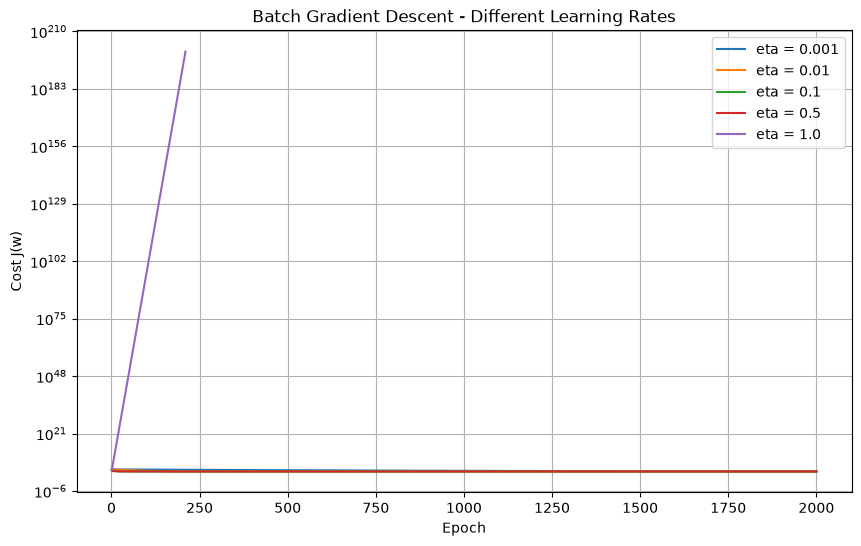

In [26]:
plt.figure(figsize=(10, 6))

for eta in learning_rates:
    plt.plot(
        range(1, epochs + 1),
        gd_results[eta]["costs"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Batch Gradient Descent - Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
results_table = pd.DataFrame([
    {
        "Learning Rate": eta,
        "Final Cost": gd_results[eta]["final_cost"],
        "Final Relative Distance": gd_results[eta]["final_distance"],
        "First Epoch < 1e-3": gd_results[eta]["first_epoch"]
    }
    for eta in learning_rates
])

results_table

,Learning Rate,Final Cost,Final Relative Distance,First Epoch < 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,inf,inf,not reached


The learning rate affects how fast gradient descent converges. The learning rate 0.5 was the fastest and reached the required accuracy at epoch 1524. The learning rate 1.0 diverged.

### B

In [28]:
X_train_bias = add_bias(X_train)
N = X_train_bias.shape[0]

H = (X_train_bias.T @ X_train_bias) / N

lambda_max = np.max(np.linalg.eigvalsh(H))
eta_threshold = 2 / lambda_max

print("Lambda max:", lambda_max)
print("Learning rate threshold:", eta_threshold)

Lambda max: 3.9547550320503744
Learning rate threshold: 0.5057203249737277


In [29]:
eta_converge = 0.95 * eta_threshold
eta_diverge = 1.05 * eta_threshold

threshold_results = {}

for eta in [eta_converge, eta_diverge]:
    w, costs, distances = batch_gradient_descent(
        X_train, y_train, eta, epochs, w_star
    )

    threshold_results[eta] = {
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1]
    }

print("Converging eta:", eta_converge)
print("Final cost:", threshold_results[eta_converge]["final_cost"])

print("\nDiverging eta:", eta_diverge)
print("Final cost:", threshold_results[eta_diverge]["final_cost"])

Converging eta: 0.4804343087250412
Final cost: 1491.145909733976

Diverging eta: 0.5310063412224141
Final cost: 3.2448118178716657e+168


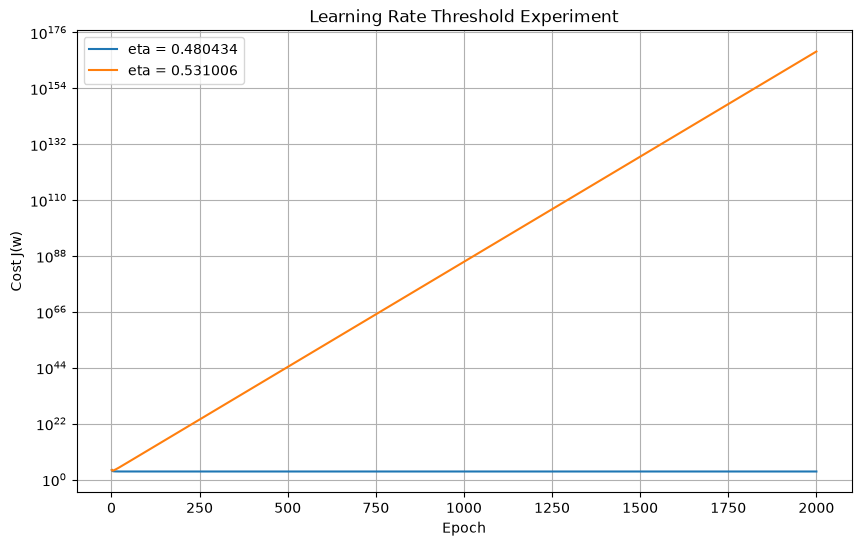

In [30]:
plt.figure(figsize=(10, 6))

for eta, result in threshold_results.items():
    plt.plot(
        range(1, epochs + 1),
        result["costs"],
        label=f"eta = {eta:.6f}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Learning Rate Threshold Experiment")
plt.legend()
plt.grid(True)
plt.show()

The learning rate (0.95(2/\lambda_{\max})) converges, while (1.05(2/\lambda_{\max})) diverges.

From the error equation:

[
e^{(t+1)}=(I-\eta H)e^{(t)}
]

For gradient descent to converge, the learning rate must satisfy:

[
\boxed{0<\eta<\frac{2}{\lambda_{\max}}}
]

Therefore, (2/\lambda_{\max}) is the maximum learning-rate threshold for convergence.

## 7

In [31]:
X_raw = splits["Diabetes"]["X_train"]
y_train = splits["Diabetes"]["y_train"]

X_raw_bias = add_bias(X_raw)

H_raw = (X_raw_bias.T @ X_raw_bias) / len(y_train)

lambda_max_raw = np.max(np.linalg.eigvalsh(H_raw))
threshold_raw = 2 / lambda_max_raw

condition_raw = np.linalg.cond(X_raw_bias.T @ X_raw_bias)

print("Raw condition number:", condition_raw)
print("Raw learning rate threshold:", threshold_raw)

Raw condition number: 55778473.21993696
Raw learning rate threshold: 2.7427928748390996e-05


In [32]:
w_star_raw = normal_equation(X_raw, y_train)
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

for eta in raw_learning_rates:
    w, costs, distances = batch_gradient_descent(
        X_raw, y_train, eta, 2000, w_star_raw
    )

    raw_results[eta] = {
        "weights": w,
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1]
    }

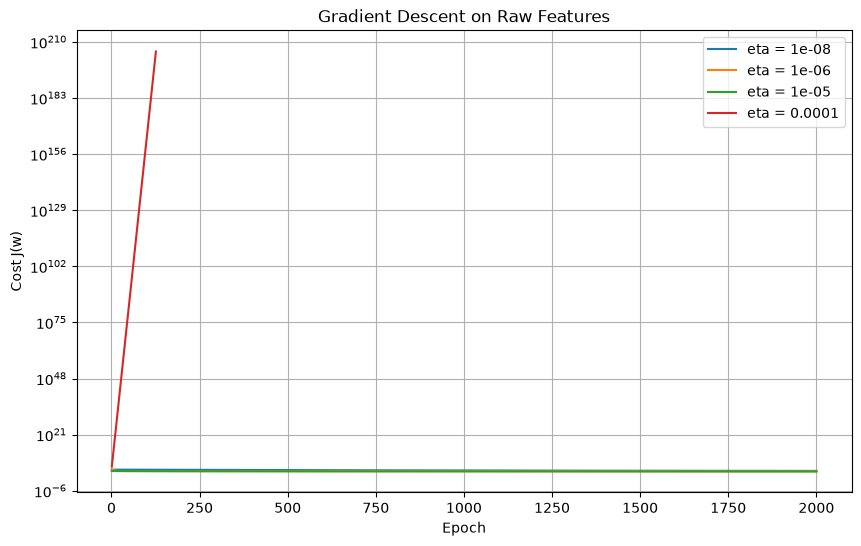

In [33]:
plt.figure(figsize=(10, 6))

for eta in raw_learning_rates:
    plt.plot(
        range(1, 2001),
        raw_results[eta]["costs"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Gradient Descent on Raw Features")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
raw_results_table = pd.DataFrame([
    {
        "Learning Rate": eta,
        "Final Cost": result["final_cost"],
        "Final Relative Distance": result["final_distance"],
        "First Epoch < 1e-3": next(
            (i + 1 for i, d in enumerate(result["distances"]) if d < 1e-3),
            "not reached"
        )
    }
    for eta, result in raw_results.items()
])

raw_results_table

,Learning Rate,Final Cost,Final Relative Distance,First Epoch < 1e-3
0,1.000000e-08,3583.532102,0.999999,not reached
1,1.000000e-06,2388.752582,0.999968,not reached
2,1.000000e-05,1827.534910,0.999846,not reached
3,1.000000e-04,inf,inf,not reached


In [35]:
X_std_bias = add_bias(X_train)
H_std = (X_std_bias.T @ X_std_bias) / len(y_train)

lambda_max_std = np.max(np.linalg.eigvalsh(H_std))

comparison = pd.DataFrame({
    "": ["Standardized", "Raw"],
    "Condition Number": [
        np.linalg.cond(X_std_bias.T @ X_std_bias),
        condition_raw
    ],
    "Learning Rate Threshold": [
        2 / lambda_max_std,
        threshold_raw
    ]
})

comparison

,,Condition Number,Learning Rate Threshold
0,Standardized,5.057061e+02,0.505720
1,Raw,5.577847e+07,0.000027


Standardized features have a much smaller condition number than raw features. This allows gradient descent to use larger learning rates. Raw features require much smaller learning rates, so convergence is slower. The learning rate \(10^{-4}\) diverges, while the other raw runs do not reach the optimal cost within 2000 epochs.

## 8

In [36]:
def mini_batch_gd(X, y, eta, epochs, batch_size):
    X_bias = add_bias(X)
    N = len(y)

    w = np.zeros(X_bias.shape[1])
    rng = np.random.default_rng(42)

    epoch_costs = []
    update_costs = []

    for epoch in range(epochs):
        indices = rng.permutation(N)

        for start in range(0, N, batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X_bias[batch]
            y_batch = y[batch]

            gradient = X_batch.T @ (X_batch @ w - y_batch) / len(batch)
            w -= eta * gradient

            error = X_bias @ w - y
            update_costs.append((error @ error) / (2 * N))

        epoch_costs.append(update_costs[-1])

    return w, epoch_costs, update_costs

In [37]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

N = len(y_train)
batch_sizes = [1, 16, 64, N]

mini_results = {}

for B in batch_sizes:
    w, epoch_costs, update_costs = mini_batch_gd(
        X_train, y_train,
        eta=0.01,
        epochs=100,
        batch_size=B
    )

    mini_results[B] = {
        "weights": w,
        "epoch_costs": epoch_costs,
        "update_costs": update_costs
    }

print(mini_results[1].keys())

dict_keys(['weights', 'epoch_costs', 'update_costs'])


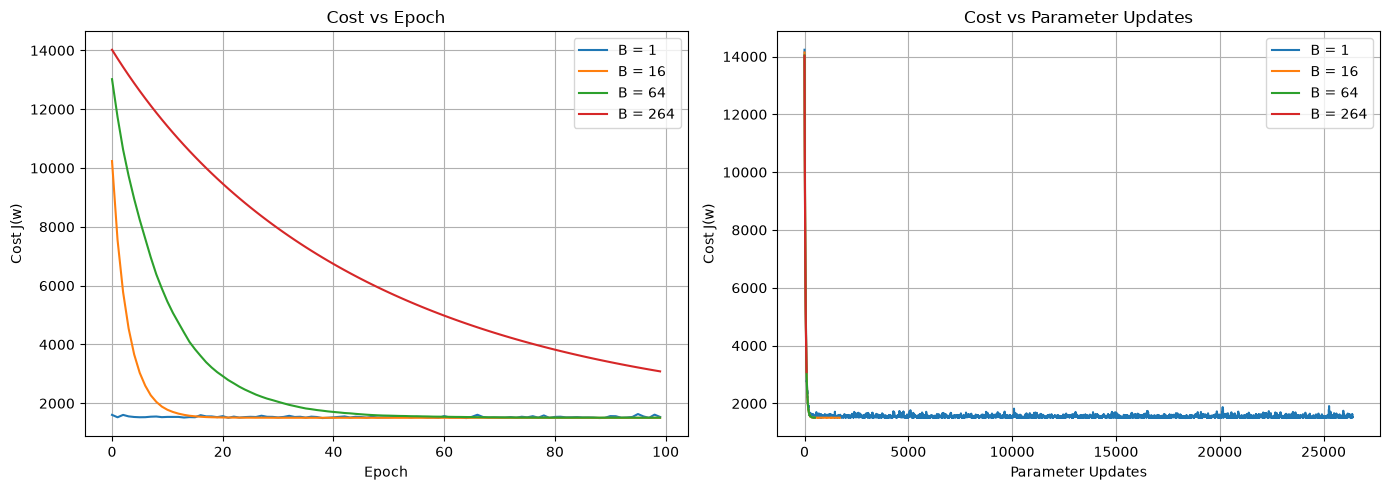

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:
    axes[0].plot(
        mini_results[B]["epoch_costs"],
        label=f"B = {B}"
    )

    axes[1].plot(
        mini_results[B]["update_costs"],
        label=f"B = {B}"
    )

axes[0].set_title("Cost vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cost J(w)")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Cost vs Parameter Updates")
axes[1].set_xlabel("Parameter Updates")
axes[1].set_ylabel("Cost J(w)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [39]:
sgd_rates = [0.001, 0.01, 0.1]

sgd_results = {}

for eta in sgd_rates:
    w, costs, update_costs = mini_batch_gd(
        X_train, y_train,
        eta=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = update_costs

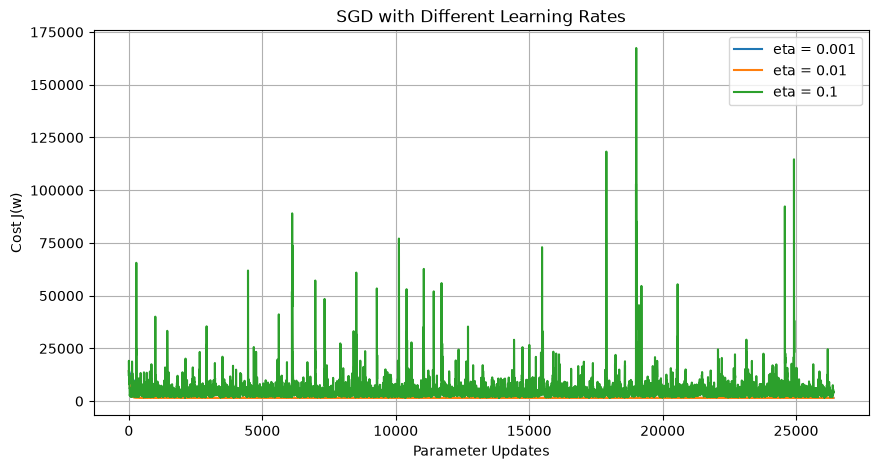

In [40]:
plt.figure(figsize=(10, 5))

for eta in sgd_rates:
    plt.plot(
        sgd_results[eta],
        label=f"eta = {eta}"
    )

plt.xlabel("Parameter Updates")
plt.ylabel("Cost J(w)")
plt.title("SGD with Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

As the learning rate increases, the noise in SGD also increases. With a learning rate of 0.001, the updates are smaller and the cost curve is smoother. At 0.01, the fluctuations become more noticeable. At 0.1, the updates are much larger, causing greater fluctuations in the cost. Therefore, higher learning rates make SGD noisier.

## 9

In [41]:
def ridge_regression(X, y, lam):
    X_bias = add_bias(X)
    N = len(y)

    I0 = np.eye(X_bias.shape[1])
    I0[0, 0] = 0

    A = (X_bias.T @ X_bias) / N + lam * I0
    b = (X_bias.T @ y) / N

    w = np.linalg.solve(A, b)

    return w

In [42]:
X_example = np.array([[1], [2], [3]])
y_example = np.array([2, 3, 5])

w_ridge = ridge_regression(X_example, y_example, lam=1)

print(w_ridge)

[2.13333333 0.6       ]


In [43]:
def degree2_features(X):
    features = [X]
    names = list(diabetes.feature_names)

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            # Drop sex squared (sex is feature index 1)
            if i == 1 and j == 1:
                continue

            features.append((X[:, i] * X[:, j]).reshape(-1, 1))
            names.append(f"{diabetes.feature_names[i]}*{diabetes.feature_names[j]}")

    return np.column_stack(features), names


# Use the original, unstandardized splits
data = splits["Diabetes"]

X_train_exp, feature_names_exp = degree2_features(data["X_train"])
X_val_exp, _ = degree2_features(data["X_val"])
X_test_exp, _ = degree2_features(data["X_test"])

# Standardize using training statistics only
exp_scaler = Standardizer()

X_train_exp = exp_scaler.fit(X_train_exp).transform(X_train_exp)
X_val_exp = exp_scaler.transform(X_val_exp)
X_test_exp = exp_scaler.transform(X_test_exp)

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

print("Number of expanded features:", X_train_exp.shape[1])

Number of expanded features: 64


In [44]:
X_exp_bias = add_bias(X_train_exp)

condition_expanded = np.linalg.cond(
    X_exp_bias.T @ X_exp_bias
)

print("Expanded condition number:", condition_expanded)

Expanded condition number: 1289356234.781073


In [45]:
lambdas = np.concatenate(([0], np.logspace(-3, 1, 9)))

X_original = scaled_splits["Diabetes"]["X_train"]
X_val_original = scaled_splits["Diabetes"]["X_val"]
X_test_original = scaled_splits["Diabetes"]["X_test"]

datasets_ridge = {
    "Original": (
        X_original, X_val_original, X_test_original
    ),
    "Expanded": (
        X_train_exp, X_val_exp, X_test_exp
    )
}

ridge_results = {}

for name, (Xtr, Xva, Xte) in datasets_ridge.items():

    results = []

    for lam in lambdas:
        w = ridge_regression(Xtr, y_train, lam)

        val_pred = add_bias(Xva) @ w
        test_pred = add_bias(Xte) @ w

        results.append({
            "lambda": lam,
            "weights": w,
            "val_rmse": rmse(y_val, val_pred),
            "test_rmse": rmse(y_test, test_pred)
        })

    ridge_results[name] = results

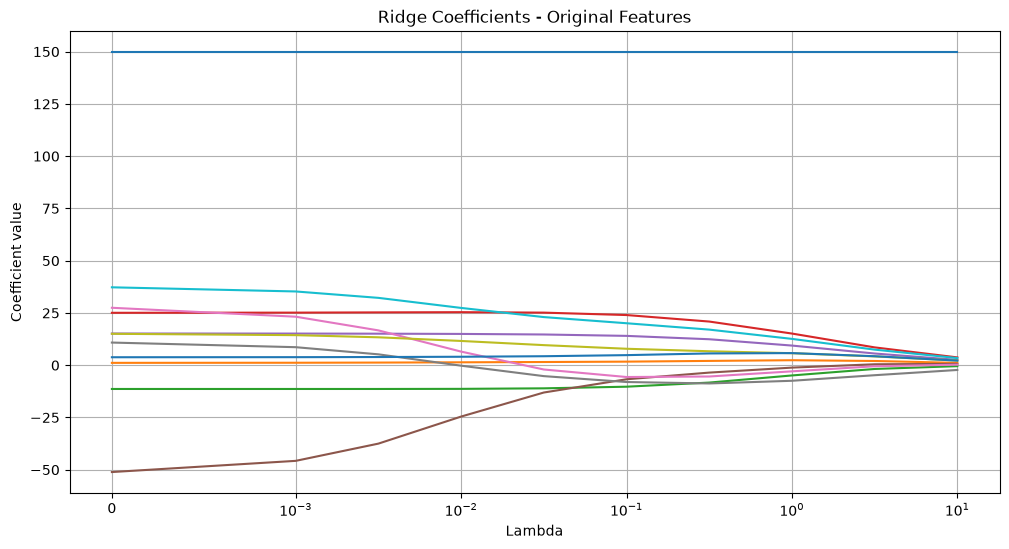

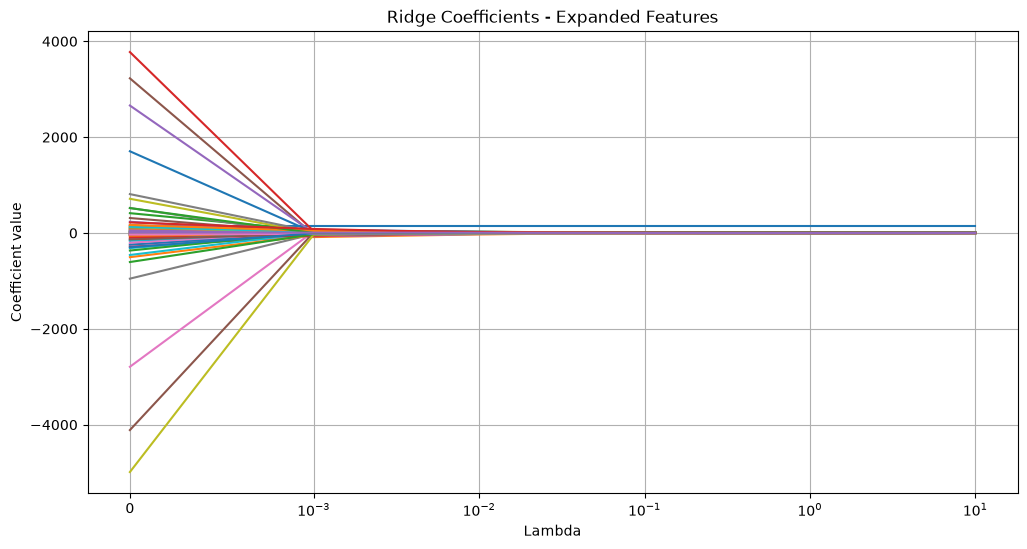

In [46]:
for name in ["Original", "Expanded"]:

    plt.figure(figsize=(12, 6))

    for i in range(len(ridge_results[name][0]["weights"])):
        coefficients = [
            result["weights"][i]
            for result in ridge_results[name]
        ]

        plt.plot(lambdas, coefficients, label=f"w{i}")

    plt.xscale("symlog", linthresh=0.001)
    plt.xlabel("Lambda")
    plt.ylabel("Coefficient value")
    plt.title(f"Ridge Coefficients - {name} Features")
    plt.grid(True)
    plt.show()

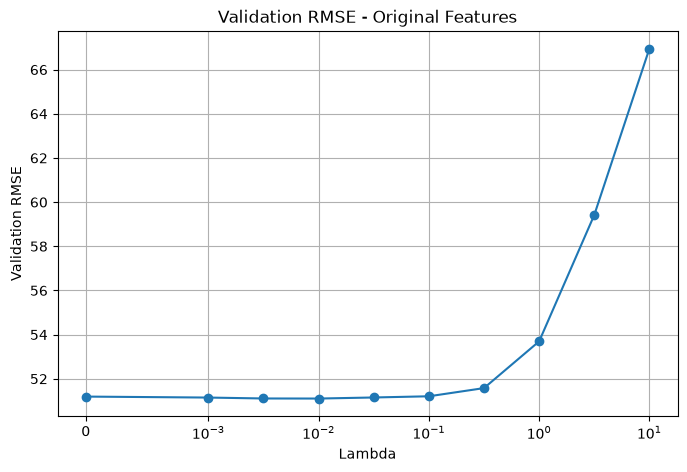

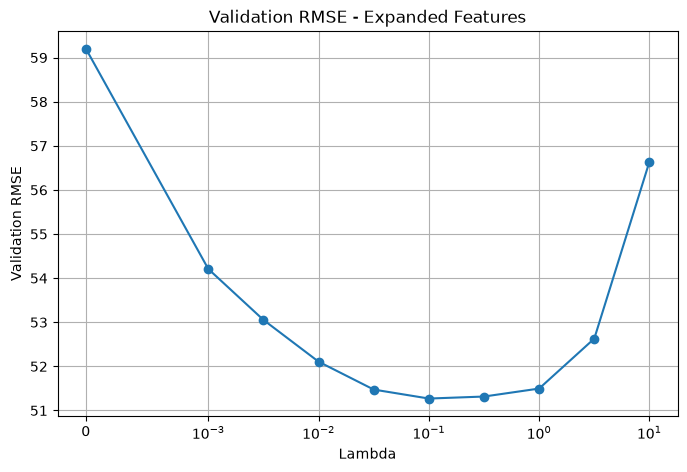

In [47]:
for name in ["Original", "Expanded"]:

    val_errors = [
        result["val_rmse"]
        for result in ridge_results[name]
    ]

    plt.figure(figsize=(8, 5))
    plt.plot(lambdas, val_errors, marker="o")

    plt.xscale("symlog", linthresh=0.001)
    plt.xlabel("Lambda")
    plt.ylabel("Validation RMSE")
    plt.title(f"Validation RMSE - {name} Features")
    plt.grid(True)
    plt.show()

In [48]:
for name in ["Original", "Expanded"]:

    best_result = min(
        ridge_results[name],
        key=lambda result: result["val_rmse"]
    )

    zero_result = ridge_results[name][0]

    print(f"\n{name} Features")
    print("Best lambda:", best_result["lambda"])
    print("Best validation RMSE:", best_result["val_rmse"])
    print("Test RMSE at best lambda:", best_result["test_rmse"])
    print("Test RMSE at lambda = 0:", zero_result["test_rmse"])


Original Features
Best lambda: 0.01
Best validation RMSE: 51.104749050571826
Test RMSE at best lambda: 53.9584521494208
Test RMSE at lambda = 0: 54.15641293326045

Expanded Features
Best lambda: 0.1
Best validation RMSE: 51.270639772934246
Test RMSE at best lambda: 53.61558011674492
Test RMSE at lambda = 0: 62.133373394532775


In [49]:
lam = 0.1
eta = 0.4
epochs = 3000

X_bias = add_bias(X_original)
N = len(y_train)

H = (X_bias.T @ X_bias) / N
b = (X_bias.T @ y_train) / N

w = np.zeros(X_bias.shape[1])

for epoch in range(epochs):
    gradient = H @ w - b

    # Do not regularize the bias
    gradient[1:] += lam * w[1:]

    w -= eta * gradient

w_ridge_closed = ridge_regression(
    X_original, y_train, lam
)

distance = (
    np.linalg.norm(w - w_ridge_closed)
    / np.linalg.norm(w_ridge_closed)
)

print("Relative distance:", distance)

Relative distance: 2.334012474785855e-16


In [50]:
ridge_model = Ridge(alpha=lam * N)

ridge_model.fit(X_original, y_train)

w_sklearn_ridge = np.concatenate(
    ([ridge_model.intercept_],
     ridge_model.coef_)
)

print(
    "Scratch vs sklearn Ridge difference:",
    np.linalg.norm(w_ridge_closed - w_sklearn_ridge)
)

Scratch vs sklearn Ridge difference: 2.0800069107082593e-13


Ridge provides a small improvement with the 10 original features because the number of features (d = 10) is much smaller than the number of training samples (N = 264), so overfitting is already limited. However, with the degree-2 expansion, we have 64 features compared to only 264 training samples, which increases the risk of overfitting. Ridge regularization reduces large coefficients and improves generalization, leading to a larger improvement in validation RMSE. The bias must not be penalized because it controls the model's baseline prediction, and penalizing it would unnecessarily force the intercept toward zero.

## 10

In [51]:

X_train = scaled_splits["Diabetes"]["X_train"]
X_test = scaled_splits["Diabetes"]["X_test"]

y_train = splits["Diabetes"]["y_train"]
y_test = splits["Diabetes"]["y_test"]

N_train = len(y_train)

def relative_distance(w, w_star):
    return np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

In [52]:
start = time.perf_counter()
w_star = normal_equation(X_train, y_train)
normal_time = time.perf_counter() - start

print("Normal equation time:", normal_time)

Normal equation time: 0.0003053999971598387


In [53]:
def evaluate_model(name, w, fit_time):
    predictions = add_bias(X_test) @ w

    return {
        "Model": name,
        "Test RMSE": rmse(y_test, predictions),
        "Relative Distance": relative_distance(w, w_star),
        "Fit Time (seconds)": fit_time
    }

In [54]:
results = []

# 1. Normal Equation
results.append(
    evaluate_model("Normal Equation", w_star, normal_time)
)


# 2. Batch Gradient Descent
start = time.perf_counter()

w_batch, costs, distances = batch_gradient_descent(
    X_train, y_train,
    eta=0.5,
    epochs=2000,
    w_star=w_star
)

batch_time = time.perf_counter() - start

results.append(
    evaluate_model("Batch GD", w_batch, batch_time)
)


# 3. Mini-batch Gradient Descent
start = time.perf_counter()

w_mini, costs, update_costs = mini_batch_gd(
    X_train, y_train,
    eta=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start

results.append(
    evaluate_model("Mini-batch GD (B=16)", w_mini, mini_time)
)


# 4. Ridge Regression (from scratch)
start = time.perf_counter()

w_ridge = ridge_regression(X_train, y_train, lam=0.1)

ridge_time = time.perf_counter() - start

results.append(
    evaluate_model("Ridge (scratch)", w_ridge, ridge_time)
)

In [55]:
# 5. LinearRegression
start = time.perf_counter()

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_time = time.perf_counter() - start

w_linear = np.concatenate(([linear_model.intercept_], linear_model.coef_))

results.append(
    evaluate_model("LinearRegression", w_linear, linear_time)
)


# 6. Ridge from sklearn
start = time.perf_counter()

ridge_model = Ridge(alpha=0.1 * N_train)
ridge_model.fit(X_train, y_train)

sk_ridge_time = time.perf_counter() - start

w_sk_ridge = np.concatenate(([ridge_model.intercept_], ridge_model.coef_))

results.append(
    evaluate_model("Ridge (sklearn)", w_sk_ridge, sk_ridge_time)
)

In [56]:
sgd_rates = [0.001, 0.01, 0.1]

for eta in sgd_rates:
    start = time.perf_counter()

    sgd_model = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    sgd_model.fit(X_train, y_train)

    sgd_time = time.perf_counter() - start

    w_sgd = np.concatenate(([sgd_model.intercept_[0]], sgd_model.coef_))

    results.append(
        evaluate_model(f"SGDRegressor (eta={eta})", w_sgd, sgd_time)
    )

In [57]:
results_df = pd.DataFrame(results)
results_df

,Model,Test RMSE,Relative Distance,Fit Time (seconds)
0,Normal Equation,54.156413,0.000000e+00,0.000305
1,Batch GD,54.156254,1.546262e-04,0.059264
2,Mini-batch GD (B=16),53.895449,3.421471e-01,0.032768
3,Ridge (scratch),53.708925,3.636136e-01,0.000188
4,LinearRegression,54.156413,7.419598e-15,0.001522
5,Ridge (sklearn),53.708925,3.636136e-01,0.000908
6,SGDRegressor (eta=0.001),54.088486,4.976050e-02,0.014032
7,SGDRegressor (eta=0.01),54.898061,5.031993e-02,0.013636
8,SGDRegressor (eta=0.1),71.449348,3.949685e-01,0.013212


In [58]:
print("Normal Equation vs LinearRegression:")
print(np.linalg.norm(w_star - w_linear))

print("\nRidge scratch vs Ridge sklearn:")
print(np.linalg.norm(w_ridge - w_sk_ridge))

Normal Equation vs LinearRegression:
1.2535866956069757e-12

Ridge scratch vs Ridge sklearn:
2.0800069107082593e-13


The Normal Equation and LinearRegression agree almost exactly, and the scratch Ridge and sklearn Ridge also agree because they use equivalent mathematical formulas and regularization parameters. However, Batch GD, Mini-batch GD, and SGDRegressor may differ from the exact solutions because they use iterative optimization rather than solving directly. Their results depend on the learning rate, number of updates, batch size, and convergence behavior.

# Part C


# 11


In [59]:
def sigmoid(z):
    result = np.empty_like(z, dtype=float)
    positive = z >= 0
    result[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1 + exp_z)
    return result


def logistic_loss(X, y, w, lam=0.0):
    z = X @ w
    data_loss = np.mean(np.logaddexp(0, z) - y * z)
    reg_loss = (lam / 2) * np.sum(w[1:] ** 2)
    return data_loss + reg_loss


def logistic_grad(X, y, w, lam=0.0):
    z = X @ w
    p = sigmoid(z)
    grad = (X.T @ (p - y)) / len(y)
    grad[1:] += lam * w[1:]
    return grad


X_train = scaled_splits["Breast Cancer"]["X_train"]
y_train = scaled_splits["Breast Cancer"]["y_train"]

X_train_log = np.c_[np.ones(X_train.shape[0]), X_train]

z_example = np.array([-800.0, 800.0])

with np.errstate(over="ignore"):
    naive_sigmoid = 1 / (1 + np.exp(-z_example))

stable_sigmoid = sigmoid(z_example)

print("Naive sigmoid:", naive_sigmoid)
print("Stable sigmoid:", stable_sigmoid)

lam = 0.1
rng = np.random.default_rng(42)
w_check = rng.normal(0, 0.1, X_train_log.shape[1])

f = lambda w: logistic_loss(X_train_log, y_train, w, lam)
grad = lambda w: logistic_grad(X_train_log, y_train, w, lam)

relative_error = grad_check(f, grad, w_check, epsilon=1e-5)

print("Gradient check relative error:", relative_error)

Naive sigmoid: [0. 1.]
Stable sigmoid: [0. 1.]
Gradient check relative error: 1.7775135713047355e-11


# 12


   lambda  train_accuracy  val_accuracy  val_loss  weight_norm  fit_time
0   0.000        0.994135      0.973684  0.084192     8.132231  0.554398
1   0.001        0.988270      0.973684  0.086207     5.099928  0.557567
2   0.010        0.985337      0.973684  0.110010     2.325749  0.548011
3   0.100        0.973607      0.973684  0.202665     1.105547  0.534806
4   1.000        0.938416      0.956140  0.389668     0.441485  0.537836
Best lambda: 0.0
Test accuracy: 0.9736842105263158


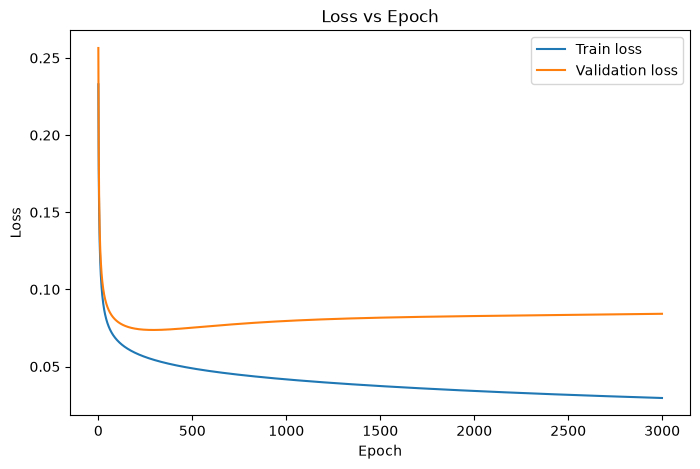

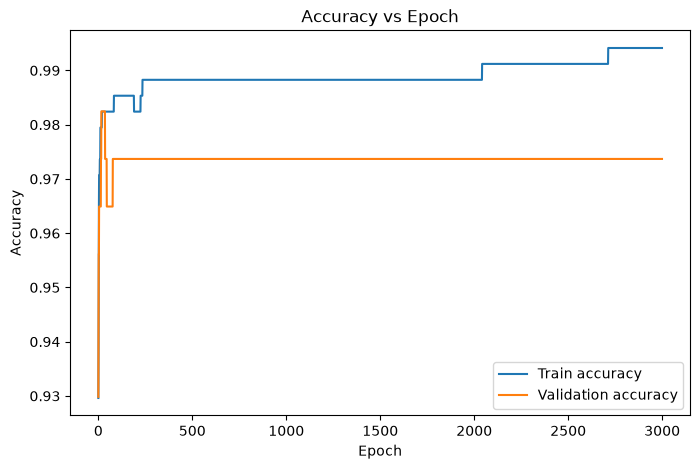

In [60]:


X_train = scaled_splits["Breast Cancer"]["X_train"]
X_val = scaled_splits["Breast Cancer"]["X_val"]
X_test = scaled_splits["Breast Cancer"]["X_test"]

y_train = scaled_splits["Breast Cancer"]["y_train"]
y_val = scaled_splits["Breast Cancer"]["y_val"]
y_test = scaled_splits["Breast Cancer"]["y_test"]

X_train_log = np.c_[np.ones(X_train.shape[0]), X_train]
X_val_log = np.c_[np.ones(X_val.shape[0]), X_val]
X_test_log = np.c_[np.ones(X_test.shape[0]), X_test]

lambdas = [0, 1e-3, 1e-2, 1e-1, 1]
learning_rate = 0.5
epochs = 3000

results = []
histories = {}
models = {}

for lam in lambdas:
    w = np.zeros(X_train_log.shape[1])
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    start_time = time.perf_counter()

    for epoch in range(epochs):
        grad = logistic_grad(X_train_log, y_train, w, lam)
        w -= learning_rate * grad

        train_losses.append(logistic_loss(X_train_log, y_train, w, lam))
        val_losses.append(logistic_loss(X_val_log, y_val, w, lam))

        train_pred = (sigmoid(X_train_log @ w) >= 0.5).astype(int)
        val_pred = (sigmoid(X_val_log @ w) >= 0.5).astype(int)

        train_accuracies.append(accuracy(y_train, train_pred))
        val_accuracies.append(accuracy(y_val, val_pred))

    fit_time = time.perf_counter() - start_time

    models[lam] = w
    histories[lam] = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "train_accuracy": train_accuracies,
        "val_accuracy": val_accuracies
    }

    results.append({
        "lambda": lam,
        "train_accuracy": train_accuracies[-1],
        "val_accuracy": val_accuracies[-1],
        "val_loss": val_losses[-1],
        "weight_norm": np.linalg.norm(w[1:]),
        "fit_time": fit_time
    })

results_df = pd.DataFrame(results)
print(results_df)

best_lambda = results_df.loc[results_df["val_loss"].idxmin(), "lambda"]
best_w = models[best_lambda]

test_pred = (sigmoid(X_test_log @ best_w) >= 0.5).astype(int)
print("Best lambda:", best_lambda)
print("Test accuracy:", accuracy(y_test, test_pred))

best_history = histories[best_lambda]

plt.figure(figsize=(8, 5))
plt.plot(best_history["train_loss"], label="Train loss")
plt.plot(best_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(best_history["train_accuracy"], label="Train accuracy")
plt.plot(best_history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.show()

# 13

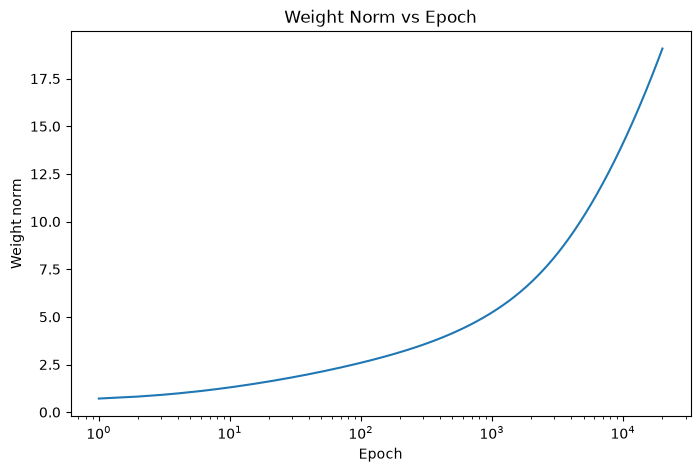

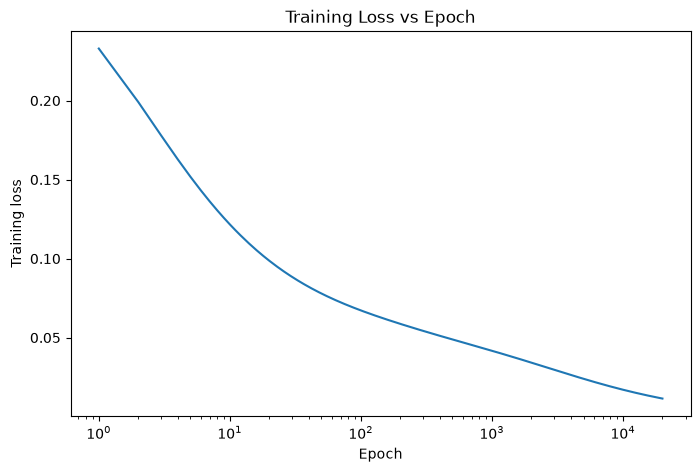

In [61]:
w = np.zeros(X_train_log.shape[1])
weight_norms = []
train_losses = []

for epoch in range(20000):
    grad = logistic_grad(X_train_log, y_train, w, lam=0)
    w -= 0.5 * grad

    weight_norms.append(np.linalg.norm(w[1:]))
    train_losses.append(logistic_loss(X_train_log, y_train, w, lam=0))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 20001), weight_norms)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Weight norm")
plt.title("Weight Norm vs Epoch")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, 20001), train_losses)
plt.xscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss vs Epoch")
plt.show()

# 14

In [62]:



sklearn_models = {}
sklearn_results = []

N_train = len(y_train)

for lam in lambdas:
    if lam == 0:
        model = LogisticRegression(
            C=np.inf,
            solver="lbfgs",
            max_iter=100000
        )
    else:
        C = 1 / (lam * N_train)

        model = LogisticRegression(
            C=C,
            solver="lbfgs",
            max_iter=100000
        )

    model.fit(X_train, y_train)
    sklearn_models[lam] = model

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    sklearn_results.append({
        "lambda": lam,
        "train_accuracy": accuracy(y_train, train_pred),
        "val_accuracy": accuracy(y_val, val_pred),
        "test_accuracy": accuracy(y_test, test_pred)
    })

sklearn_results_df = pd.DataFrame(sklearn_results)
print(sklearn_results_df)


   lambda  train_accuracy  val_accuracy  test_accuracy
0   0.000        1.000000      0.964912       0.964912
1   0.001        0.988270      0.973684       0.973684
2   0.010        0.985337      0.973684       0.982456
3   0.100        0.973607      0.973684       0.973684
4   1.000        0.938416      0.956140       0.921053


Comparing logistic regression weights with Scikit-learn's weights.

In [63]:

lam = 0.01

w_own = np.zeros(X_train_log.shape[1])

for epoch in range(3000):
    grad = logistic_grad(X_train_log, y_train, w_own, lam)
    w_own -= 0.5 * grad

C = 1 / (lam * N_train)

sk_model = LogisticRegression(
    C=C,
    solver="lbfgs",
    tol=1e-12,
    max_iter=100000
)

sk_model.fit(X_train, y_train)

w_sklearn = np.r_[sk_model.intercept_, sk_model.coef_.ravel()]

relative_error = (
    np.linalg.norm(w_own - w_sklearn)
    / max(np.linalg.norm(w_own), np.linalg.norm(w_sklearn), 1e-12)
)

own_pred = (sigmoid(X_test_log @ w_own) >= 0.5).astype(int)
sk_pred = sk_model.predict(X_test)

predictions_agree = np.array_equal(own_pred, sk_pred)

print("Our weights:", w_own)
print("Sklearn weights:", w_sklearn)
print("Relative error:", relative_error)
print("Test predictions agree:", predictions_agree)


Our weights: [-0.42381639  0.45272781  0.4263065   0.43913875  0.43804957  0.29735916
 -0.02913227  0.48050766  0.68415539 -0.06778635 -0.25009878  0.51799216
  0.00371988  0.31396651  0.43284878  0.1006227  -0.37107719 -0.04554
  0.25970854 -0.07377749 -0.40369869  0.60473948  0.89740173  0.53914398
  0.55938958  0.48909878  0.05929756  0.45633731  0.5185686   0.58966178
 -0.00755816]
Sklearn weights: [-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956  0.29735929
 -0.02913226  0.48050726  0.68415511 -0.06778639 -0.25009845  0.51799241
  0.00372002  0.31396622  0.43284867  0.10062251 -0.37107717 -0.04553991
  0.25970891 -0.07377761 -0.40369878  0.60473964  0.89740166  0.53914392
  0.55938939  0.48909906  0.05929757  0.45633758  0.51856848  0.58966202
 -0.00755869]
Relative error: 5.38960808824705e-07
Test predictions agree: True


Sweep different values of C.

In [64]:

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

C_results = []

C_models = {}

for C in C_values:
    model = LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=100000
    )

    model.fit(X_train, y_train)

    C_models[C] = model

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    C_results.append({
        "C": C,
        "train_accuracy": accuracy(y_train, train_pred),
        "val_accuracy": accuracy(y_val, val_pred),
        "test_accuracy": accuracy(y_test, test_pred)
    })

C_results_df = pd.DataFrame(C_results)

print(C_results_df)


          C  train_accuracy  val_accuracy  test_accuracy
0     0.001        0.879765      0.903509       0.868421
1     0.010        0.950147      0.964912       0.947368
2     0.100        0.979472      0.982456       0.982456
3     1.000        0.988270      0.973684       0.973684
4    10.000        0.997067      0.964912       0.964912
5   100.000        1.000000      0.956140       0.956140
6  1000.000        1.000000      0.947368       0.956140


Compare the solvers lbfgs, liblinear, and saga

In [65]:



solvers = ["lbfgs", "liblinear", "saga"]

solver_results = []

solver_models = {}

for solver in solvers:
    model = LogisticRegression(
        C=1,
        solver=solver,
        max_iter=100000,
        tol=1e-8,
        random_state=42
    )

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    fit_time = time.perf_counter() - start_time

    solver_models[solver] = model

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    solver_results.append({
        "solver": solver,
        "train_accuracy": accuracy(y_train, train_pred),
        "val_accuracy": accuracy(y_val, val_pred),
        "iterations": model.n_iter_[0],
        "fit_time": fit_time,
        "coefficient_norm": np.linalg.norm(model.coef_)
    })

solver_results_df = pd.DataFrame(solver_results)

print(solver_results_df)


      solver  train_accuracy  val_accuracy  iterations  fit_time  \
0      lbfgs         0.98827      0.973684          41  0.008565   
1  liblinear         0.98827      0.973684          12  0.002988   
2       saga         0.98827      0.973684        2412  0.321102   

   coefficient_norm  
0          3.499265  
1          3.510213  
2          3.499264  


Check whether the intercept is regularized

In [66]:

for solver in solvers:
    model = solver_models[solver]

    print(solver)
    print("Intercept:", model.intercept_[0])
    print("Coefficient norm:", np.linalg.norm(model.coef_))
    print()


lbfgs
Intercept: -0.14945634493685878
Coefficient norm: 3.4992653900650703

liblinear
Intercept: -0.11771387533486234
Coefficient norm: 3.510213333876488

saga
Intercept: -0.14945728791614926
Coefficient norm: 3.4992639106105847



A false negative means that a patient has cancer but the model predicts that they are healthy, which is dangerous because it may delay treatment. A false positive means that a healthy patient is predicted to have cancer, which may cause stress and lead to unnecessary medical tests. In a screening setting, false negatives are usually more dangerous because missing a cancer case can have serious consequences. We should not fully trust the threshold (τ) because it was chosen using only 43 positive validation cases, so it may not work equally well on new patients.

# 15

In [67]:
lam = 0.01

X_train = scaled_splits["Breast Cancer"]["X_train"]
X_val = scaled_splits["Breast Cancer"]["X_val"]
X_test = scaled_splits["Breast Cancer"]["X_test"]

y_train = scaled_splits["Breast Cancer"]["y_train"]
y_val = scaled_splits["Breast Cancer"]["y_val"]
y_test = scaled_splits["Breast Cancer"]["y_test"]

X_train_log = np.c_[np.ones(X_train.shape[0]), X_train]
X_val_log = np.c_[np.ones(X_val.shape[0]), X_val]
X_test_log = np.c_[np.ones(X_test.shape[0]), X_test]

w = np.zeros(X_train_log.shape[1])

for epoch in range(3000):
    grad = logistic_grad(X_train_log, y_train, w, lam)
    w -= 0.5 * grad

test_scores = sigmoid(X_test_log @ w)
test_pred = (test_scores >= 0.5).astype(int)

cm = confusion_matrix(y_test, test_pred, 2)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[72  0]
 [ 2 40]]


Precision, Recall, and F1-Score Results

In [68]:
TP = cm[1, 1]
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]

precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Precision: 1.0
Recall: 0.9523809523809523
F1-score: 0.975609756097561


In [69]:
def roc_curve_scratch(y, scores):
    thresholds = np.sort(np.unique(scores))[::-1]

    tpr = []
    fpr = []

    P = np.sum(y == 1)
    N = np.sum(y == 0)

    for threshold in thresholds:
        pred = (scores >= threshold).astype(int)

        TP = np.sum((y == 1) & (pred == 1))
        FP = np.sum((y == 0) & (pred == 1))

        tpr.append(TP / P)
        fpr.append(FP / N)

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    tpr = np.r_[0, tpr, 1]
    fpr = np.r_[0, fpr, 1]

    return fpr, tpr

In [70]:
def auc_scratch(fpr, tpr):
    order = np.argsort(fpr)
    fpr = fpr[order]
    tpr = tpr[order]

    return np.trapezoid(tpr, fpr)

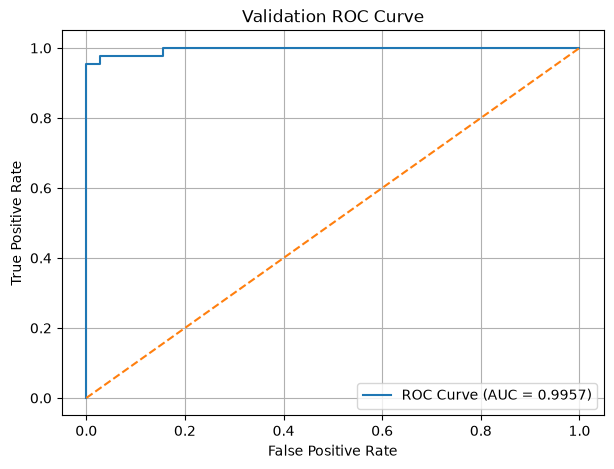

AUC from scratch: 0.9957418932197839


In [71]:
val_scores = sigmoid(X_val_log @ w)

val_fpr, val_tpr = roc_curve_scratch(y_val, val_scores)

val_auc = auc_scratch(val_fpr, val_tpr)

plt.figure(figsize=(7, 5))
plt.plot(val_fpr, val_tpr, label=f"ROC Curve (AUC = {val_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("AUC from scratch:", val_auc)

In [72]:


sklearn_auc = roc_auc_score(y_val, val_scores)

print("AUC from scratch:", val_auc)
print("AUC from sklearn:", sklearn_auc)
print("Difference:", abs(val_auc - sklearn_auc))

AUC from scratch: 0.9957418932197839
AUC from sklearn: 0.9957418932197838
Difference: 1.1102230246251565e-16


In [73]:
thresholds = np.sort(np.unique(val_scores))

valid_thresholds = []

for threshold in thresholds:
    pred = (val_scores >= threshold).astype(int)

    TP = np.sum((y_val == 1) & (pred == 1))
    FN = np.sum((y_val == 1) & (pred == 0))

    recall = TP / (TP + FN)

    if recall == 1:
        valid_thresholds.append(threshold)

best_threshold = max(valid_thresholds)

print("Best threshold:", best_threshold)

Best threshold: 0.14602532493304418


Verifying the threshold

In [74]:
val_pred_best = (val_scores >= best_threshold).astype(int)

TP = np.sum((y_val == 1) & (val_pred_best == 1))
FN = np.sum((y_val == 1) & (val_pred_best == 0))

val_recall = TP / (TP + FN)

print("Best threshold:", best_threshold)
print("Validation recall:", val_recall)
print("False negatives:", FN)

Best threshold: 0.14602532493304418
Validation recall: 1.0
False negatives: 0


In [75]:
new_test_pred = (test_scores >= best_threshold).astype(int)

new_cm = confusion_matrix(y_test, new_test_pred, 2)

TP = new_cm[1, 1]
TN = new_cm[0, 0]
FP = new_cm[0, 1]
FN = new_cm[1, 0]

new_precision = TP / (TP + FP)
new_recall = TP / (TP + FN)
new_f1 = 2 * new_precision * new_recall / (new_precision + new_recall)

print("Confusion Matrix:")
print(new_cm)

print("Precision:", new_precision)
print("Recall:", new_recall)
print("F1-score:", new_f1)

Confusion Matrix:
[[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762
F1-score: 0.9213483146067415


# 16


In [76]:


indices = np.arange(len(x_cancer))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_cancer
)

train_indices, val_indices = train_test_split(
    train_indices,
    test_size=0.25,
    random_state=42,
    stratify=y_cancer[train_indices]
)

X_train_two = x_cancer[train_indices][:, [0, 1]]
X_val_two = x_cancer[val_indices][:, [0, 1]]
X_test_two = x_cancer[test_indices][:, [0, 1]]

y_train_two = y_cancer[train_indices]
y_val_two = y_cancer[val_indices]
y_test_two = y_cancer[test_indices]

In [77]:
scaler_two = Standardizer()

X_train_two_scaled = scaler_two.fit(X_train_two).transform(X_train_two)
X_val_two_scaled = scaler_two.transform(X_val_two)
X_test_two_scaled = scaler_two.transform(X_test_two)

In [78]:
X_train_two_log = np.c_[np.ones(X_train_two_scaled.shape[0]), X_train_two_scaled]
X_val_two_log = np.c_[np.ones(X_val_two_scaled.shape[0]), X_val_two_scaled]
X_test_two_log = np.c_[np.ones(X_test_two_scaled.shape[0]), X_test_two_scaled]

In [79]:
w_two = np.zeros(X_train_two_log.shape[1])

for epoch in range(5000):
    grad = logistic_grad(X_train_two_log, y_train_two, w_two, lam=0)
    w_two -= 0.5 * grad

print("Weights:", w_two)

Weights: [-0.7271724   3.65679417  1.00987153]


In [80]:
w_original = w_two[1:] / scaler_two.std

b_original = w_two[0] - np.sum(
    w_two[1:] * scaler_two.mean / scaler_two.std
)

print("Original weights:", w_original)
print("Original bias:", b_original)

Original weights: [1.01746116 0.23190058]
Original bias: -19.643444167251356


In [81]:
scores_scaled = X_test_two_log @ w_two

scores_original = (
    b_original
    + X_test_two[:, 0] * w_original[0]
    + X_test_two[:, 1] * w_original[1]
)

print("Maximum difference:", np.max(np.abs(scores_scaled - scores_original)))

Maximum difference: 3.552713678800501e-15


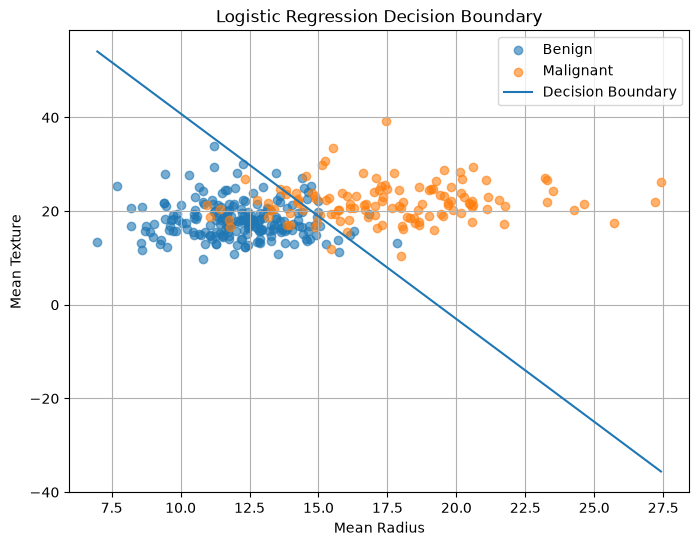

In [82]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_two[y_train_two == 0, 0],
    X_train_two[y_train_two == 0, 1],
    label="Benign",
    alpha=0.6
)

plt.scatter(
    X_train_two[y_train_two == 1, 0],
    X_train_two[y_train_two == 1, 1],
    label="Malignant",
    alpha=0.6
)

x_line = np.linspace(
    X_train_two[:, 0].min(),
    X_train_two[:, 0].max(),
    100
)

if abs(w_original[1]) > 1e-12:
    y_line = (-b_original - w_original[0] * x_line) / w_original[1]
    plt.plot(x_line, y_line, label="Decision Boundary")

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

# Part D

# TASK 17

# PREPARING DIGITS DATASET

In [83]:
X_train_digits = scaled_splits["Digits"]["X_train"]
X_val_digits = scaled_splits["Digits"]["X_val"]
X_test_digits = scaled_splits["Digits"]["X_test"]

y_train_digits = scaled_splits["Digits"]["y_train"]
y_val_digits = scaled_splits["Digits"]["y_val"]
y_test_digits = scaled_splits["Digits"]["y_test"]

K = 10

print("Training:", X_train_digits.shape)
print("Validation:", X_val_digits.shape)
print("Testing:", X_test_digits.shape)

Training: (1077, 64)
Validation: (360, 64)
Testing: (360, 64)


# ADDING BIAS COLUMN

In [84]:
X_train_digits_tilde = np.c_[np.ones(len(X_train_digits)), X_train_digits]
X_val_digits_tilde = np.c_[np.ones(len(X_val_digits)), X_val_digits]
X_test_digits_tilde = np.c_[np.ones(len(X_test_digits)), X_test_digits]

print(X_train_digits_tilde.shape)

(1077, 65)


# IMPLEMENTING STABLE SOFTMAX

In [85]:
def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_S = np.exp(S_shifted)
    return exp_S / np.sum(exp_S, axis=1, keepdims=True)

# SOFTMAX SHIFT INVARIANCE

In [86]:
def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_S = np.exp(S_shifted)
    return exp_S / np.sum(exp_S, axis=1, keepdims=True)

# VERYIFING 


In [87]:
s = np.array([[1000, 1001, 1002]])

print("Softmax:", softmax(s))
print("Shifted Softmax:", softmax(s + 500))

Softmax: [[0.09003057 0.24472847 0.66524096]]
Shifted Softmax: [[0.09003057 0.24472847 0.66524096]]


# IMPLEMNTING SOFTMAX LOSS

In [88]:
def softmax_loss(X, y, W, lam=0.0):
    S = X @ W
    log_sum_exp = np.logaddexp.reduce(S, axis=1)
    correct_scores = S[np.arange(len(y)), y]

    data_loss = np.mean(log_sum_exp - correct_scores)
    reg_loss = (lam / 2) * np.sum(W[1:] ** 2)

    return data_loss + reg_loss

# SOFTMAX GRAD

In [89]:
def softmax_grad(X, y, W, lam=0.0):
    P = softmax(X @ W)
    Y = np.eye(W.shape[1])[y]

    grad = (X.T @ (P - Y)) / len(y)
    grad[1:] += lam * W[1:]

    return grad

# Check the loss at W = 0

In [90]:
W_zero = np.zeros((65, 10))

loss_zero = softmax_loss(
    X_train_digits_tilde,
    y_train_digits,
    W_zero
)

print("Loss at W = 0:", loss_zero)
print("Expected loss:", np.log(10))

Loss at W = 0: 2.3025850929940455
Expected loss: 2.302585092994046


# CHECKING ON 100 DIFFRENT ENTRIES

In [91]:
def softmax_grad_check(X, y, W, lam=0.1, epsilon=1e-5,
                       loss_fn=softmax_loss, grad_fn=softmax_grad):
    rng = np.random.default_rng(42)

    analytical = grad_fn(X, y, W, lam)

    indices = rng.choice(W.size, 100, replace=False)

    numerical = np.zeros(100)

    for j, index in enumerate(indices):
        i, k = np.unravel_index(index, W.shape)

        W_plus = W.copy()
        W_minus = W.copy()

        W_plus[i, k] += epsilon
        W_minus[i, k] -= epsilon

        loss_plus = loss_fn(X, y, W_plus, lam)
        loss_minus = loss_fn(X, y, W_minus, lam)

        numerical[j] = (loss_plus - loss_minus) / (2 * epsilon)

    analytical_selected = analytical.ravel()[indices]

    numerator = np.linalg.norm(analytical_selected - numerical)

    denominator = max(
        np.linalg.norm(analytical_selected),
        np.linalg.norm(numerical),
        1e-12
    )

    return numerator / denominator

In [92]:
rng = np.random.default_rng(42)

W_random = rng.normal(0, 0.1, size=(65, 10))

error = softmax_grad_check(
    X_train_digits_tilde,
    y_train_digits,
    W_random,
    lam=0.1
)

print("Gradient check relative error:", error)

Gradient check relative error: 7.798672272290349e-10


# TASK 18

# Mini-batch Gradient Descent function

In [93]:
def train_softmax(X_train, y_train, X_val, y_val, eta, lam, epochs=100, batch_size=64,
                  loss_fn=softmax_loss, grad_fn=softmax_grad):
    W = np.zeros((X_train.shape[1], len(np.unique(y_train))))
    rng = np.random.default_rng(42)

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):
        indices = rng.permutation(len(y_train))

        for start in range(0, len(y_train), batch_size):
            batch_indices = indices[start:start + batch_size]

            X_batch = X_train[batch_indices]
            y_batch = y_train[batch_indices]

            grad = grad_fn(X_batch, y_batch, W, lam)
            W -= eta * grad

        train_losses.append(loss_fn(X_train, y_train, W))
        val_losses.append(loss_fn(X_val, y_val, W))

        train_pred = np.argmax(X_train @ W, axis=1)
        val_pred = np.argmax(X_val @ W, axis=1)

        train_accuracies.append(accuracy(y_train, train_pred))
        val_accuracies.append(accuracy(y_val, val_pred))

    return W, train_losses, val_losses, train_accuracies, val_accuracies

# TEST THE LEARNING RATES

In [94]:
learning_rates = [0.01, 0.1, 0.5, 1.0]

eta_results = []
eta_models = {}

for eta in learning_rates:
    W, train_loss, val_loss, train_acc, val_acc = train_softmax(
        X_train_digits_tilde,
        y_train_digits,
        X_val_digits_tilde,
        y_val_digits,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    eta_models[eta] = W

    eta_results.append({
        "eta": eta,
        "train_loss": train_loss[-1],
        "val_loss": val_loss[-1],
        "train_accuracy": train_acc[-1],
        "val_accuracy": val_acc[-1]
    })

eta_results_df = pd.DataFrame(eta_results)
print(eta_results_df)

    eta  train_loss  val_loss  train_accuracy  val_accuracy
0  0.01    0.808641  0.837388        0.924791      0.911111
1  0.10    0.203817  0.238951        0.960074      0.950000
2  0.50    0.086785  0.138329        0.988858      0.961111
3  1.00    0.056569  0.119327        0.996286      0.961111


# PLOT THE RESULTS

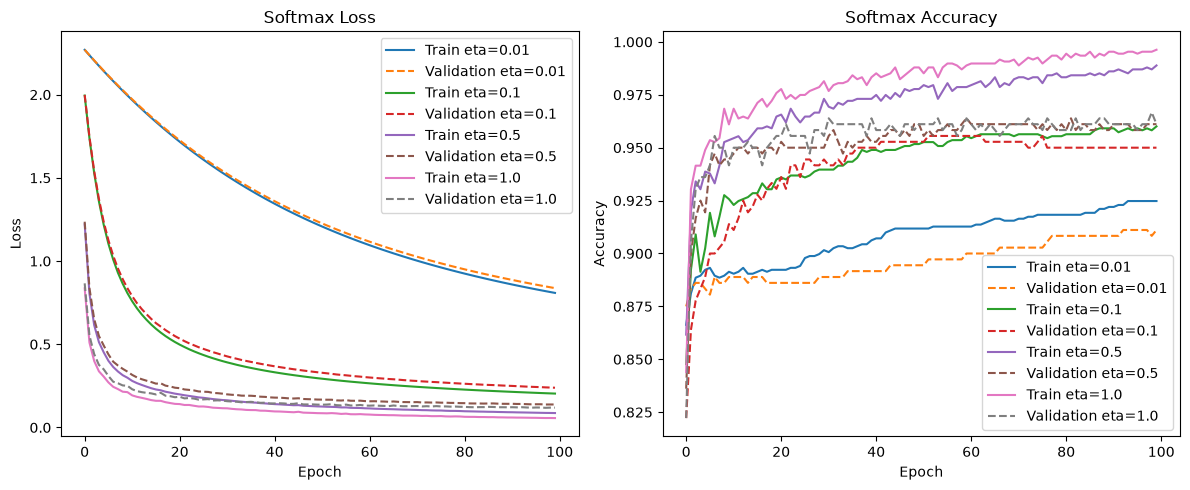

In [95]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

for eta in learning_rates:
    W, train_loss, val_loss, train_acc, val_acc = train_softmax(
        X_train_digits_tilde,
        y_train_digits,
        X_val_digits_tilde,
        y_val_digits,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    plt.plot(train_loss, label=f"Train eta={eta}")
    plt.plot(val_loss, linestyle="--", label=f"Validation eta={eta}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Softmax Loss")
plt.legend()

plt.subplot(1, 2, 2)

for eta in learning_rates:
    W, train_loss, val_loss, train_acc, val_acc = train_softmax(
        X_train_digits_tilde,
        y_train_digits,
        X_val_digits_tilde,
        y_val_digits,
        eta=eta,
        lam=0,
        epochs=100,
        batch_size=64
    )

    plt.plot(train_acc, label=f"Train eta={eta}")
    plt.plot(val_acc, linestyle="--", label=f"Validation eta={eta}")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Softmax Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

# THE BEST LEARNING RATE

In [96]:
best_eta = eta_results_df.loc[
    eta_results_df["val_loss"].idxmin(), "eta"
]

print("Best learning rate:", best_eta)

Best learning rate: 1.0


# TEST REGULARIZATION VALUES

In [97]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]

lambda_results = []
lambda_models = {}

for lam in lambdas:
    W, train_loss, val_loss, train_acc, val_acc = train_softmax(
        X_train_digits_tilde,
        y_train_digits,
        X_val_digits_tilde,
        y_val_digits,
        eta=best_eta,
        lam=lam,
        epochs=100,
        batch_size=64
    )

    lambda_models[lam] = W

    lambda_results.append({
        "lambda": lam,
        "train_accuracy": train_acc[-1],
        "val_accuracy": val_acc[-1],
        "train_loss": train_loss[-1],
        "val_loss": val_loss[-1]
    })

lambda_results_df = pd.DataFrame(lambda_results)
print(lambda_results_df)

   lambda  train_accuracy  val_accuracy  train_loss  val_loss
0  0.0000        0.996286      0.961111    0.056569  0.119327
1  0.0001        0.996286      0.963889    0.064993  0.124232
2  0.0010        0.980501      0.966667    0.136004  0.182245
3  0.0100        0.938719      0.927778    0.424953  0.464233
4  0.1000        0.641597      0.633333    1.355525  1.383951


# CHOOSING LAMBDA

In [98]:

best_lambda = lambda_results_df.sort_values(
    ["val_accuracy", "lambda"],
    ascending=[False, False]
).iloc[0]["lambda"]

best_W = lambda_models[best_lambda]

test_pred = np.argmax(
    softmax(X_test_digits_tilde @ best_W),
    axis=1
)

test_accuracy = accuracy(y_test_digits, test_pred)

print("Best lambda:", best_lambda)
print("Test accuracy:", test_accuracy)

Best lambda: 0.001
Test accuracy: 0.9527777777777777


In [99]:
softmax_result = lambda_results_df.loc[lambda_results_df["lambda"] == best_lambda].iloc[0]
softmax_test_accuracy = test_accuracy
softmax_settings = (best_eta, best_lambda)

# TASK 18

# COMPARINING LAMBDA VALUES

In [100]:
N_train = len(y_train_digits)

sklearn_lambda_results = []
sklearn_lambda_models = {}

for lam in lambdas:
    if lam == 0:
        C = np.inf
    else:
        C = 1 / (lam * N_train)

    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_digits, y_train_digits)

    sklearn_lambda_models[lam] = model

    val_pred = model.predict(X_val_digits)
    test_pred = model.predict(X_test_digits)

    sklearn_lambda_results.append({
        "lambda": lam,
        "C": C,
        "val_accuracy": accuracy(y_val_digits, val_pred),
        "test_accuracy": accuracy(y_test_digits, test_pred)
    })

sklearn_lambda_df = pd.DataFrame(sklearn_lambda_results)
print(sklearn_lambda_df)

   lambda         C  val_accuracy  test_accuracy
0  0.0000       inf      0.955556       0.955556
1  0.0001  9.285051      0.975000       0.961111
2  0.0010  0.928505      0.972222       0.955556
3  0.0100  0.092851      0.947222       0.933333
4  0.1000  0.009285      0.902778       0.886111


# COMPARE MODEL WITH SCIKIT-LEARN

In [101]:
comparison = lambda_results_df.merge(
    sklearn_lambda_df,
    on="lambda",
    suffixes=("_scratch", "_sklearn")
)

print(comparison)

   lambda  train_accuracy  val_accuracy_scratch  train_loss  val_loss  \
0  0.0000        0.996286              0.961111    0.056569  0.119327   
1  0.0001        0.996286              0.963889    0.064993  0.124232   
2  0.0010        0.980501              0.966667    0.136004  0.182245   
3  0.0100        0.938719              0.927778    0.424953  0.464233   
4  0.1000        0.641597              0.633333    1.355525  1.383951   

          C  val_accuracy_sklearn  test_accuracy  
0       inf              0.955556       0.955556  
1  9.285051              0.975000       0.961111  
2  0.928505              0.972222       0.955556  
3  0.092851              0.947222       0.933333  
4  0.009285              0.902778       0.886111  


# SWEEP DIFFRENT C VALUES

In [102]:
C_values = [0.1, 1, 10, 100]

C_results = []

for C in C_values:
    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_digits, y_train_digits)

    val_pred = model.predict(X_val_digits)
    test_pred = model.predict(X_test_digits)

    C_results.append({
        "C": C,
        "val_accuracy": accuracy(y_val_digits, val_pred),
        "test_accuracy": accuracy(y_test_digits, test_pred)
    })

C_results_df = pd.DataFrame(C_results)
print(C_results_df)

       C  val_accuracy  test_accuracy
0    0.1      0.950000       0.938889
1    1.0      0.972222       0.955556
2   10.0      0.963889       0.955556
3  100.0      0.961111       0.955556


# CHECK PREDICITION AGREEMENT 

In [103]:
sklearn_best_model = sklearn_lambda_models[best_lambda]

scratch_test_pred = np.argmax(
    softmax(X_test_digits_tilde @ best_W),
    axis=1
)

sklearn_test_pred = sklearn_best_model.predict(X_test_digits)

agreement = accuracy(scratch_test_pred, sklearn_test_pred)

print("Prediction agreement:", agreement)
print("Prediction agreement percentage:", agreement * 100)

Prediction agreement: 0.9916666666666667
Prediction agreement percentage: 99.16666666666667


# TASK 19



We compared our Softmax implementation with Scikit-learn's Logistic Regression using equivalent regularization values. We also tested different C values to understand how regularization affects the model. Finally, we compared the test predictions from both implementations to check how closely they agree.

# TASK 20

# CONFUSSION MATRIX

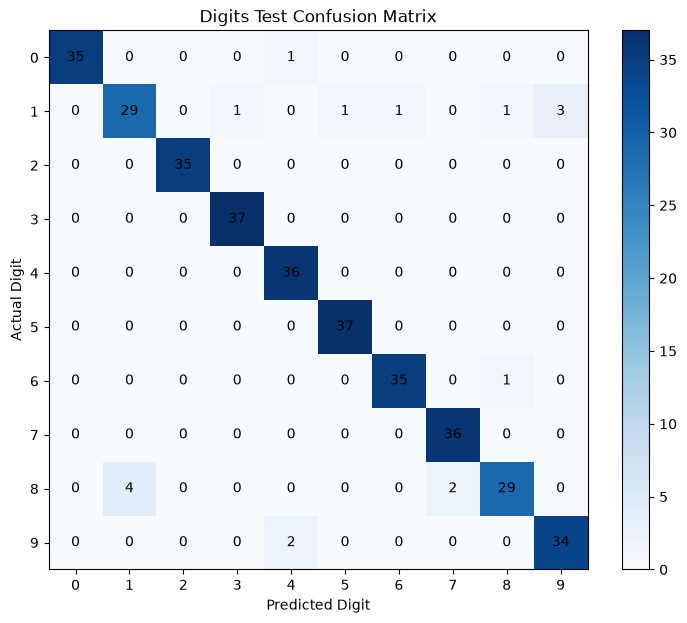

In [104]:
cm_digits = confusion_matrix(
    y_test_digits,
    scratch_test_pred,
    10
)

plt.figure(figsize=(9, 7))
plt.imshow(cm_digits, cmap="Blues")
plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Digits Test Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm_digits[i, j], ha="center", va="center")

plt.show()

# Per-class precision, recall, and F1

In [105]:
TP = np.diag(cm_digits)

precision_per_class = np.divide(
    TP,
    np.sum(cm_digits, axis=0),
    out=np.zeros(10, dtype=float),
    where=np.sum(cm_digits, axis=0) != 0
)

recall_per_class = np.divide(
    TP,
    np.sum(cm_digits, axis=1),
    out=np.zeros(10, dtype=float),
    where=np.sum(cm_digits, axis=1) != 0
)

f1_per_class = np.divide(
    2 * precision_per_class * recall_per_class,
    precision_per_class + recall_per_class,
    out=np.zeros(10, dtype=float),
    where=(precision_per_class + recall_per_class) != 0
)

class_metrics = pd.DataFrame({
    "Digit": range(10),
    "Precision": precision_per_class,
    "Recall": recall_per_class,
    "F1": f1_per_class
})

print(class_metrics)
print("Macro Precision:", np.mean(precision_per_class))
print("Macro Recall:", np.mean(recall_per_class))
print("Macro F1:", np.mean(f1_per_class))

   Digit  Precision    Recall        F1
0      0   1.000000  0.972222  0.985915
1      1   0.878788  0.805556  0.840580
2      2   1.000000  1.000000  1.000000
3      3   0.973684  1.000000  0.986667
4      4   0.923077  1.000000  0.960000
5      5   0.973684  1.000000  0.986667
6      6   0.972222  0.972222  0.972222
7      7   0.947368  1.000000  0.972973
8      8   0.935484  0.828571  0.878788
9      9   0.918919  0.944444  0.931507
Macro Precision: 0.9523226656078949
Macro Recall: 0.9523015873015874
Macro F1: 0.951531845973415


# Find the three most confused pairs

In [106]:
cm_off_diagonal = cm_digits.copy()
np.fill_diagonal(cm_off_diagonal, 0)

confused_pairs = []

for _ in range(3):
    i, j = np.unravel_index(
        np.argmax(cm_off_diagonal),
        cm_off_diagonal.shape
    )

    confused_pairs.append({
        "True Digit": i,
        "Predicted Digit": j,
        "Count": cm_off_diagonal[i, j]
    })

    cm_off_diagonal[i, j] = 0

confused_pairs_df = pd.DataFrame(confused_pairs)
print(confused_pairs_df)

   True Digit  Predicted Digit  Count
0           8                1      4
1           1                9      3
2           8                7      2


# Display six misclassified digits

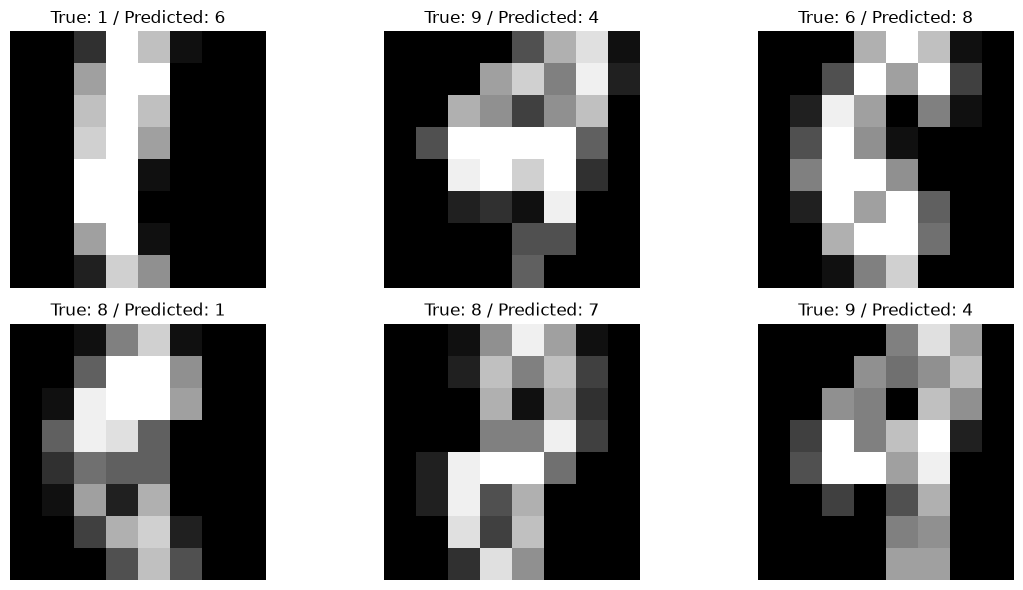

In [107]:
misclassified = np.where(
    scratch_test_pred != y_test_digits
)[0]

plt.figure(figsize=(12, 6))

for i, index in enumerate(misclassified[:6]):
    plt.subplot(2, 3, i + 1)

    plt.imshow(
        X_test_digits[index].reshape(8, 8),
        cmap="gray"
    )

    plt.title(
        f"True: {y_test_digits[index]} / Predicted: {scratch_test_pred[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Visualize the weights of the ten classes

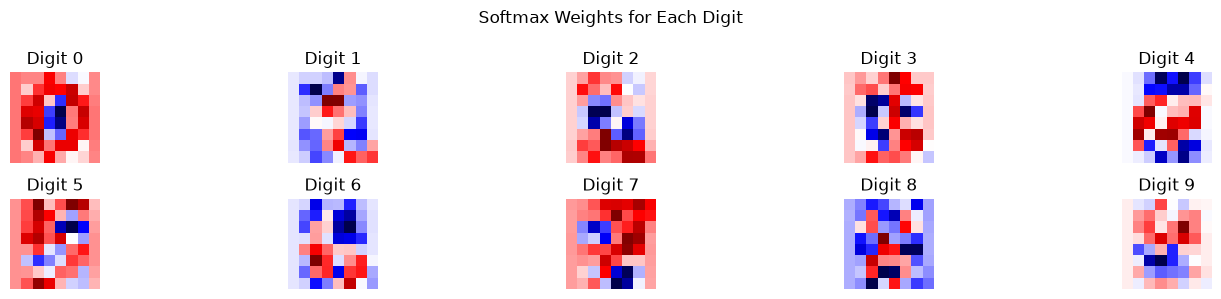

In [108]:
plt.figure(figsize=(15, 3))

for digit in range(10):
    plt.subplot(2, 5, digit + 1)

    plt.imshow(
        best_W[1:, digit].reshape(8, 8),
        cmap="seismic"
    )

    plt.title(f"Digit {digit}")
    plt.axis("off")

plt.suptitle("Softmax Weights for Each Digit")
plt.tight_layout()
plt.show()

## Task 20 — Error Analysis

The confusion matrix helps us identify which digits the model classifies correctly and which digits it confuses. Some digits are harder to recognize because they can have similar shapes or writing styles. This is understandable because our model uses a linear decision boundary and only looks at the raw pixel values. It cannot easily understand complex shapes or different handwriting styles.

# TASK 21

# GENERATE RANDOM WEIGHTS

In [109]:
rng = np.random.default_rng(42)

W_two_class = rng.normal(
    0,
    0.1,
    size=(31, 2)
)

# CALCULATE PROB USING SOFTMAX

In [110]:
P_softmax = softmax(X_test_log @ W_two_class)

prob_softmax = P_softmax[:, 1]

# CALCULATE PROB USING LOGISTIC REGRESSION

In [111]:
w_difference = W_two_class[:, 1] - W_two_class[:, 0]

prob_logistic = sigmoid(X_test_log @ w_difference)

# COMPARE

In [112]:
max_difference = np.max(
    np.abs(prob_softmax - prob_logistic)
)

print("Maximum probability difference:", max_difference)

Maximum probability difference: 1.1102230246251565e-16


## Task 21 — Softmax with K = 2 Is Logistic Regression

For two classes, the Softmax probability of class 1 can be simplified by dividing the numerator and denominator by the exponential of the class 1 score. This gives the sigmoid function applied to the difference between the two class scores. We verified this numerically using random weights and the Breast Cancer test data, and both methods produced almost identical probabilities.

# TASK 22

# SELECT AND STANDRIZE THE FEATURES

In [113]:
X_iris_two = x_iris[:, [2, 3]]

X_train_iris, X_val_iris, X_test_iris, y_train_iris, y_val_iris, y_test_iris = split_data(
    X_iris_two,
    y_iris
)

scaler_iris = Standardizer()

X_train_iris_scaled = scaler_iris.fit(X_train_iris).transform(X_train_iris)
X_val_iris_scaled = scaler_iris.transform(X_val_iris)
X_test_iris_scaled = scaler_iris.transform(X_test_iris)

X_train_iris_tilde = np.c_[np.ones(len(X_train_iris_scaled)), X_train_iris_scaled]
X_val_iris_tilde = np.c_[np.ones(len(X_val_iris_scaled)), X_val_iris_scaled]
X_test_iris_tilde = np.c_[np.ones(len(X_test_iris_scaled)), X_test_iris_scaled]

# Train full-batch Softmax

In [114]:
def train_iris_softmax(X, y, eta, lam, epochs=2000):
    W = np.zeros((X.shape[1], 3))

    for epoch in range(epochs):
        grad = softmax_grad(X, y, W, lam)
        W -= eta * grad

    return W

In [115]:
W_iris_0 = train_iris_softmax(
    X_train_iris_tilde,
    y_train_iris,
    eta=0.5,
    lam=0
)

W_iris_1 = train_iris_softmax(
    X_train_iris_tilde,
    y_train_iris,
    eta=0.5,
    lam=1
)

# IMPLEMENT DECSSION REGIONS

In [116]:
def plot_decision_regions(X, y, W, scaler, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    grid_scaled = scaler.transform(grid)
    grid_tilde = np.c_[np.ones(len(grid_scaled)), grid_scaled]

    predictions = np.argmax(
        softmax(grid_tilde @ W),
        axis=1
    )

    Z = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    for class_id in range(3):
        plt.scatter(
            X[y == class_id, 0],
            X[y == class_id, 1],
            label=f"Class {class_id}"
        )

    plt.xlabel("Petal Length")
    plt.ylabel("Petal Width")
    plt.title(title)
    plt.legend()
    plt.show()

# PLOT BOTH MODELS

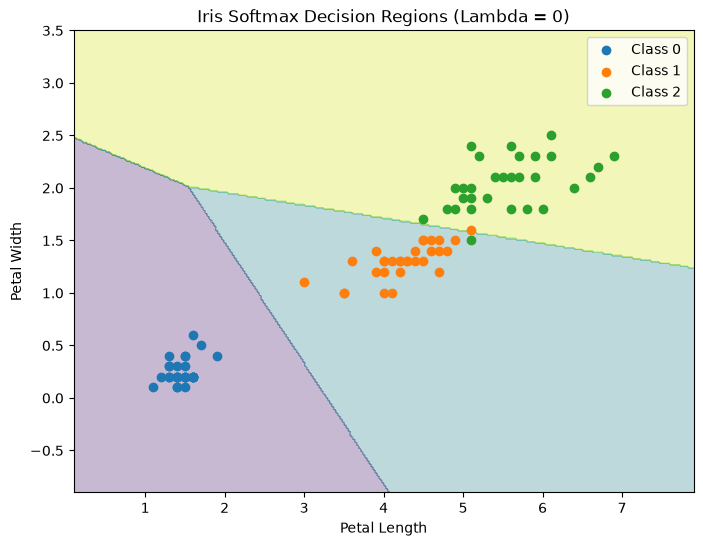

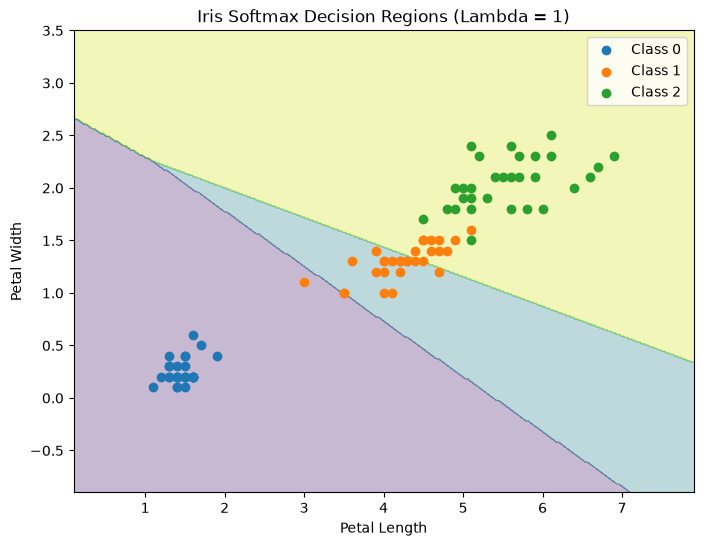

In [117]:

plot_decision_regions(
    X_train_iris,
    y_train_iris,
    W_iris_0,
    scaler_iris,
    "Iris Softmax Decision Regions (Lambda = 0)"
)

plot_decision_regions(
    X_train_iris,
    y_train_iris,
    W_iris_1,
    scaler_iris,
    "Iris Softmax Decision Regions (Lambda = 1)"
)

# COMPARE WITH SCIKIT LEARN

In [118]:
sklearn_iris_models = {}

for lam in [0, 1]:
    if lam == 0:
        C = np.inf
    else:
        C = 1 / (lam * len(y_train_iris))

    model = LogisticRegression(
        C=C,
        max_iter=10000,
        solver="lbfgs"
    )

    model.fit(X_train_iris_scaled, y_train_iris)

    sklearn_iris_models[lam] = model

In [119]:
def plot_sklearn_regions(X, y, model, scaler, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid)

    Z = model.predict(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

    for class_id in range(3):
        plt.scatter(
            X[y == class_id, 0],
            X[y == class_id, 1],
            label=f"Class {class_id}"
        )

    plt.xlabel("Petal Length")
    plt.ylabel("Petal Width")
    plt.title(title)
    plt.legend()
    plt.show()

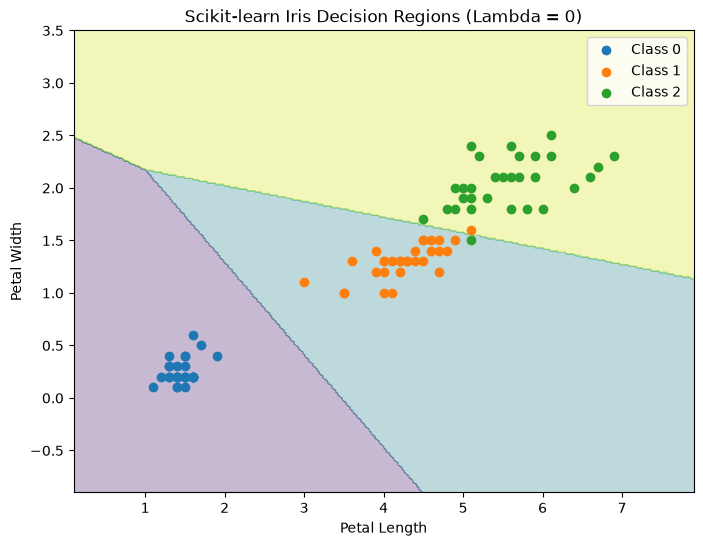

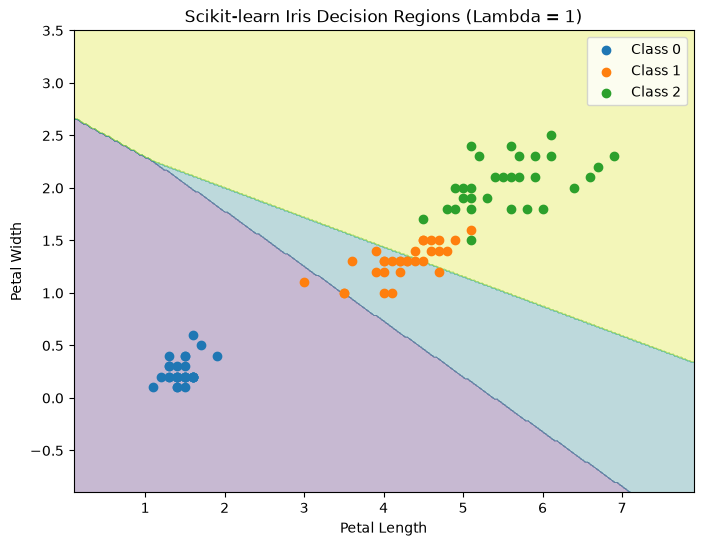

In [120]:
for lam in [0, 1]:
    plot_sklearn_regions(
        X_train_iris,
        y_train_iris,
        sklearn_iris_models[lam],
        scaler_iris,
        f"Scikit-learn Iris Decision Regions (Lambda = {lam})"
    )

## Task 22 — Seeing the Boundaries

We trained Softmax on the Iris dataset using petal length and petal width. We plotted the decision regions for lambda values of 0 and 1 and compared them with Scikit-learn's Logistic Regression. Regularization controls the size of the weights and can change the shape of the decision regions. The comparison helps us understand how regularization affects the classification boundaries.

# Part E

## 23

Below the required margin, each row contributes the negative label times its features to the gradient. Average these contributions and add the weight penalty. The bias is excluded from the penalty.

The gradient check nudges each weight up and down and compares the measured slope with the calculated one.

In [121]:
c_train, c_val, c_test = X_train_log[:, 1:], X_val_log[:, 1:], X_test_log[:, 1:]

ct, cv, ce = X_train_log, X_val_log, X_test_log

yt, yv, ye = 2 * y_train - 1, 2 * y_val - 1, 2 * y_test - 1

In [122]:
d_train, d_val, d_test = X_train_digits, X_val_digits, X_test_digits

dt, dv, de = X_train_digits_tilde, X_val_digits_tilde, X_test_digits_tilde

dyt, dyv, dye = y_train_digits, y_val_digits, y_test_digits

assert (len(yt), len(yv), len(ye)) == (341, 114, 114)

assert (len(dyt), len(dyv), len(dye)) == (1077, 360, 360)

In [123]:
def l2(w, lam):
    grad = lam * w
    grad[0] = 0

    return lam / 2 * np.sum(w[1:] ** 2), grad

def binary(X, y, w, lam):
    margins = y * (X @ w)
    loss = np.maximum(0, 1 - margins).mean()
    penalty, reg_grad = l2(w, lam)

    return loss + penalty, X.T @ (-y * (margins < 1)) / len(y) + reg_grad

def predict_binary(X, w):
    return np.where(X @ w >= 0, 1, -1)

def diminishing(t):
    return 1 / np.sqrt(t)

def fit_binary(lam, steps, rate, record=False):
    w = np.zeros(ct.shape[1])
    history = []

    for t in range(1, steps + 1):
        w -= rate(t) * binary(ct, yt, w, lam)[1]

        if record:
            objective, _ = binary(ct, yt, w, lam)
            history.append((objective, accuracy(yv, predict_binary(cv, w))))

    return w, np.array(history)

In [124]:
lam = .01

probe = np.random.default_rng(42).normal(0, .1, ct.shape[1])

assert np.min(np.abs(1 - yt * (ct @ probe))) > 1e-6 * np.abs(ct).max()

error = grad_check(lambda w: binary(ct, yt, w, lam)[0],
                   lambda w: binary(ct, yt, w, lam)[1], probe, epsilon=1e-6)

print(f"Binary relative gradient error: {error:.3g}")

assert error < 1e-5

Binary relative gradient error: 1.06e-10


Constant 0.1 final objective and validation accuracy: [0.060544 0.973684]


Constant 1.0 final objective and validation accuracy: [0.060961 0.973684]


1/sqrt(t) final objective and validation accuracy: [0.060798 0.973684]


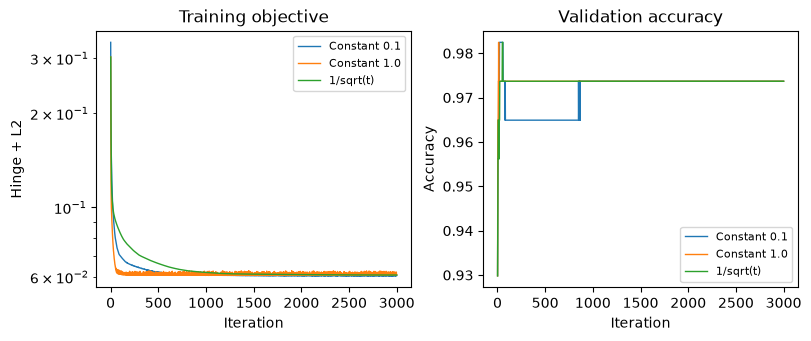

In [125]:
schedules = {"Constant 0.1": lambda t: .1, "Constant 1.0": lambda t: 1.,
             "1/sqrt(t)": diminishing}

fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), constrained_layout=True)

titles = ["Training objective", "Validation accuracy"]

for name, rate in schedules.items():
    _, history = fit_binary(lam, 3000, rate, record=True)
    print(name, "final objective and validation accuracy:", history[-1].round(6))

    for ax, values in zip(axes, history.T):
        ax.plot(np.arange(1, 3001), values, label=name, lw=1)

for ax, title, ylabel in zip(axes, titles, ("Hinge + L2", "Accuracy")):
    ax.set(title=title, xlabel="Iteration", ylabel=ylabel)
    ax.legend(fontsize=8)

axes[0].set_yscale("log")

plt.show()

The gradient can change abruptly at a hinge kink, so a fixed step can keep crossing it. Decreasing steps make these moves smaller. Constant 0.1 still gave the lowest objective after 3,000 steps (0.060544). All three runs reached 97.37% validation accuracy.

## 24

C is the reciprocal of lambda times the training-set size. SVC counts nonzero dual coefficients; our count uses points on or inside the margin. LinearSVC also penalizes the intercept.

In [126]:
def linear_svc(strength):
    return SVC(kernel="linear", C=1/(strength*len(yt)), tol=1e-9).fit(c_train, yt)

def params(model):
    return np.r_[model.intercept_, model.coef_.ravel()]

def width(w):
    return 2 / np.linalg.norm(w[1:])

def margin_count(w):
    return np.count_nonzero(yt * (ct @ w) <= 1)

In [127]:
w20, _ = fit_binary(lam, 20000, diminishing)

svc = linear_svc(lam)

ref = params(svc)

j_np, j_ref = [binary(ct, yt, w, lam)[0] for w in (w20, ref)]

gap = abs(j_np - j_ref) / abs(j_ref)

cosine = w20[1:] @ ref[1:] / (np.linalg.norm(w20[1:]) * np.linalg.norm(ref[1:]))

agree = accuracy(svc.predict(c_test), predict_binary(ce, w20))

count_gap = abs(margin_count(w20) - svc.n_support_.sum())

In [128]:
display(pd.DataFrame({"NumPy": [j_np, width(w20), margin_count(w20)],
                      "SVC": [j_ref, width(ref), svc.n_support_.sum()]},
                     index=["Objective", "Margin width", "Primal count / dual SVs"]))

for label, value, passed in (
        ("Relative objective gap", gap, gap <= 1e-3),
        ("Weight cosine", cosine, cosine >= .99),
        ("Test agreement", agree, agree >= .98),
        ("Support count difference", count_gap, count_gap <= 5)):
    print(f"{label}: {value:.8g} — {'PASS' if passed else 'OUTSIDE TARGET'}")

print("SVC rows within 1e-6 of margin:",
      np.count_nonzero(np.abs(yt * (ct @ ref) - 1) <= 1e-6))

,NumPy,SVC
Objective,0.060450,0.060434
Margin width,1.131752,1.129158
Primal count / dual SVs,28.000000,32.000000


Relative objective gap: 0.00025463944 — PASS
Weight cosine: 0.99968532 — PASS
Test agreement: 1 — PASS
Support count difference: 4 — PASS
SVC rows within 1e-6 of margin: 14


All four checks passed. The models agreed on all 114 test rows. Their support counts differed by four, with 14 SVC points very close to the margin.

In [129]:
rows = []

for strength in (1e-4, 1e-3, 1e-2, 1e-1, 1):
    C = 1 / (strength * len(yt))
    w = w20 if strength == lam else fit_binary(strength, 20000, diminishing)[0]
    libsvm = svc if strength == lam else linear_svc(strength)
    liblinear = LinearSVC(loss="hinge", dual=True, C=C, tol=1e-8,
                         max_iter=100000, random_state=42).fit(c_train, yt)

    for name, weights, sv in (("NumPy", w, None), ("SVC", params(libsvm), libsvm.n_support_.sum()),
                              ("LinearSVC", params(liblinear), None)):
        rows.append((strength, C, name, accuracy(yv, predict_binary(cv, weights)),
                     width(weights), margin_count(weights), sv,
                     binary(ct, yt, weights, strength)[0]))

In [130]:
sweep = pd.DataFrame(rows, columns=["lambda", "C", "model", "val accuracy", "width",
                                    "primal count", "dual count", "common objective"])

display(sweep.round(6))

,lambda,C,model,val accuracy,width,primal count,dual count,common objective
0,0.0001,29.325513,NumPy,0.964912,0.592339,15,NaN,0.030374
1,0.0001,29.325513,SVC,0.947368,0.146006,12,22.0,0.009382
2,0.0001,29.325513,LinearSVC,0.947368,0.145977,13,NaN,0.009386
3,0.0010,2.932551,NumPy,0.973684,0.653872,17,NaN,0.035844
4,0.0010,2.932551,SVC,0.964912,0.462153,21,28.0,0.032159
5,0.0010,2.932551,LinearSVC,0.964912,0.463393,22,NaN,0.032162
6,0.0100,0.293255,NumPy,0.973684,1.131752,28,NaN,0.060450
7,0.0100,0.293255,SVC,0.973684,1.129158,24,32.0,0.060434
8,0.0100,0.293255,LinearSVC,0.973684,1.123459,27,NaN,0.060444
9,0.1000,0.029326,NumPy,0.982456,2.168837,56,NaN,0.121683


At lambda 0.0001, NumPy still had a higher objective than SVC (0.03037 vs. 0.00938). LinearSVC differs most at strong regularization because it also penalizes the intercept.

## 25

Each rival that the correct class fails to beat by one point contributes +1 to its gradient and −1 to the correct class gradient. Multiplying by the inputs, averaging and adding the weight penalty gives the weight gradient. At zero weights, nine rivals each add one, so the loss is 9.

In [131]:
def hinge_scores(S, y):
    rows = np.arange(len(y))
    gaps = S - S[rows, y, None] + 1
    gaps[rows, y] = 0
    B = (gaps > 0).astype(float)
    B[rows, y] = -B.sum(axis=1)

    return np.maximum(gaps, 0).sum(axis=1), B

def multiclass(X, y, W, lam):
    loss, grad = hinge_scores(X @ W, y)
    penalty, reg_grad = l2(W, lam)
    mean = loss.mean()

    return mean, mean + penalty, X.T @ grad / len(y) + reg_grad

In [132]:
shape = (dt.shape[1], 10)

probe = np.random.default_rng(42).normal(0, .1, shape)

scores_check = dt @ probe

gaps_check = scores_check - scores_check[np.arange(len(dyt)), dyt, None] + 1

assert np.abs(gaps_check).min() > 1e-6 * np.abs(dt).max()

assert multiclass(dt, dyt, np.zeros(shape), 0)[0] == 9

error = softmax_grad_check(
    dt, dyt, probe, lam=.1, epsilon=1e-6,
    loss_fn=lambda X, y, W, lam: multiclass(X, y, W, lam)[1],
    grad_fn=lambda X, y, W, lam: multiclass(X, y, W, lam)[2]
)

print(f"Zero-weight hinge loss: 9. Relative gradient error: {error:.3g}")

assert error < 1e-5

Zero-weight hinge loss: 9. Relative gradient error: 4.25e-09


In [133]:
def fit_hinge(rate, strength):
    W, train_loss, val_loss, train_acc, val_acc = train_softmax(
        dt, dyt, dv, dyv, rate, strength,
        loss_fn=lambda X, y, W, lam=0: multiclass(X, y, W, lam)[1],
        grad_fn=lambda X, y, W, lam=0: multiclass(X, y, W, lam)[2]
    )

    return W, np.column_stack((train_loss, val_loss, train_acc, val_acc))

In [134]:
rate_runs = {eta: fit_hinge(eta, 0) for eta in (.01, .1, .5)}

best_eta = min(rate_runs, key=lambda eta: rate_runs[eta][1][-1, 1])

reg_runs = {0: rate_runs[best_eta]}

for strength in (1e-4, 1e-3, 1e-2):
    reg_runs[strength] = fit_hinge(best_eta, strength)

best_lam = max(reg_runs, key=lambda strength: (reg_runs[strength][1][-1, 3], strength))

W, history = reg_runs[best_lam]

print(f"Selected eta={best_eta}, lambda={best_lam}")

print(f"Validation: {history[-1, 3]:.2%}, test: {accuracy(dye, (de @ W).argmax(axis=1)):.2%}")

hinge_test_accuracy = accuracy(dye, (de @ W).argmax(axis=1))

display(pd.DataFrame({
    "Validation": [history[-1, 3], softmax_result["val_accuracy"]],
    "Test": [hinge_test_accuracy, softmax_test_accuracy]
}, index=["Multiclass hinge (E25)", "Softmax (D18)"]).round(6))

Selected eta=0.5, lambda=0.001
Validation: 96.94%, test: 95.00%


,Validation,Test
Multiclass hinge (E25),0.969444,0.950000
Softmax (D18),0.966667,0.952778


,Train loss,Validation loss,Train accuracy,Validation accuracy
eta,,,,
0.01,0.249399,0.312630,0.967502,0.950000
0.10,0.063447,0.170185,0.991643,0.961111
0.50,0.012203,0.140615,0.998143,0.961111


,Train loss,Validation loss,Train accuracy,Validation accuracy
lambda,,,,
0.0000,0.012203,0.140615,0.998143,0.961111
0.0001,0.014740,0.139525,0.997214,0.963889
0.0010,0.036440,0.153480,0.996286,0.969444
0.0100,0.204673,0.296014,0.959146,0.944444


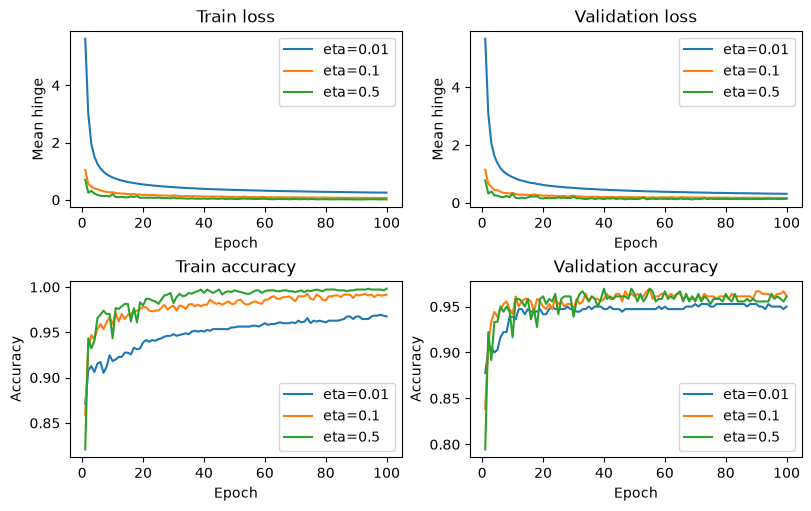

In [135]:
titles = ["Train loss", "Validation loss", "Train accuracy", "Validation accuracy"]

for setting, runs in (("eta", rate_runs), ("lambda", reg_runs)):
    table = pd.DataFrame({value: h[-1] for value, (_, h) in runs.items()}, index=titles).T
    display(table.rename_axis(setting).round(6))

fig, axes = plt.subplots(2, 2, figsize=(8, 5), constrained_layout=True)

for ax, title, index in zip(axes.flat, titles, range(4)):
    for eta, (_, h) in rate_runs.items():
        ax.plot(range(1, 101), h[:, index], label=f"eta={eta}")

    ax.set(title=title, xlabel="Epoch", ylabel="Mean hinge" if index < 2 else "Accuracy")
    ax.legend()

plt.show()

Hinge got 96.94% validation and 95.00% test accuracy. Softmax got 96.67% and 95.28%. Each difference is one image out of 360.

In [136]:
scores = np.array([[10, -5, -5], [100, -50, -50], [3.2, 5.1, -1.7]])

toy_hinge = hinge_scores(scores, np.zeros(3, dtype=int))[0]

toy_ce = np.array([
    softmax_loss(scores[0:1], np.array([0]), np.eye(3)),
    softmax_loss(scores[1:2], np.array([0]), np.eye(3)),
    softmax_loss(scores[2:3], np.array([0]), np.eye(3))
])

display(pd.DataFrame({"Hinge": toy_hinge, "Softmax loss": toy_ce}, index=list("abc")))

,Hinge,Softmax loss
a,0.0,6.118045e-07
b,0.0,0.000000e+00
c,2.9,2.040355e+00


Hinge stops penalizing a sample when all margins are met. Softmax keeps rewarding a higher probability for the correct class. Hinge scores express margins; softmax probabilities still need a calibration check.

## 26

In [137]:
models = {
    "Linear": SVC(C=1, kernel="linear"),
    "Polynomial": SVC(C=1, kernel="poly", degree=3, coef0=1, gamma="scale"),
    "RBF": SVC(C=1, kernel="rbf", gamma="scale")
}

rows = []

for name, model in models.items():
    model.fit(c_train, yt)
    rows.append([name, *(accuracy(y, model.predict(X)) for X, y in ((c_train, yt), (c_val, yv), (c_test, ye))),
                 model.n_support_.sum()])

kernel_table = pd.DataFrame(rows, columns=["Kernel", "Train", "Validation", "Test", "Support vectors"])

display(kernel_table.round(6))

,Kernel,Train,Validation,Test,Support vectors
0,Linear,0.988270,0.964912,0.929825,30
1,Polynomial,0.991202,0.982456,0.973684,52
2,RBF,0.982405,0.982456,0.973684,88


Polynomial and RBF tied at 98.25% on validation. Linear got 96.49%. Polynomial used 52 support vectors and RBF used 88.

In [138]:
rows = []

for C in (.001, .01, .1, 1, 10, 100):
    model = SVC(C=C, kernel="linear").fit(c_train, yt)
    rows.append((C, accuracy(yt, model.predict(c_train)),
                 accuracy(yv, model.predict(c_val)), model.n_support_.sum(),
                 width(params(model))))

c_table = pd.DataFrame(rows, columns=["C", "Train", "Validation", "Support vectors", "Width"])

display(c_table.round(6))

print("Margin shrinks:", (c_table.Width.diff().dropna() <= 0).all())

print("Support vectors at smallest and largest C:", c_table["Support vectors"].iloc[[0, -1]].tolist())

,C,Train,Validation,Support vectors,Width
0,0.001,0.932551,0.956140,175,6.761937
1,0.010,0.973607,0.973684,83,3.168999
2,0.100,0.979472,0.964912,43,1.566853
3,1.000,0.988270,0.964912,30,0.672679
4,10.000,0.997067,0.938596,23,0.247084
5,100.000,1.000000,0.947368,22,0.146007


Margin shrinks: True
Support vectors at smallest and largest C: [175, 22]


Larger C means weaker regularization. Support vectors fell from 175 to 22 as the margin narrowed and training accuracy rose to 100%. Validation accuracy was highest at C=0.01.

## 27

In [139]:
x2_train, x2_val = X_train_two_scaled, X_val_two_scaled

np.testing.assert_allclose(x2_train, c_train[:, :2])

np.testing.assert_allclose(x2_val, c_val[:, :2])

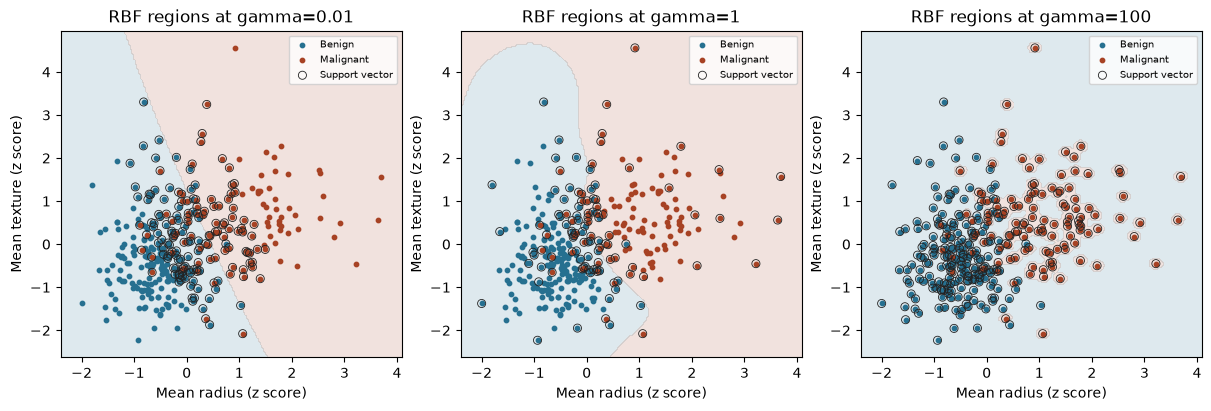

,Gamma,Train,Validation,Support vectors
0,0.01,0.882698,0.868421,166
1,0.10,0.900293,0.894737,109
2,1.00,0.912023,0.894737,108
3,10.00,0.929619,0.877193,201
4,100.00,0.982405,0.736842,311


In [140]:
rows = []

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)

panels = dict(zip((.01, 1, 100), axes))

lo, hi = x2_train.min(axis=0) - .4, x2_train.max(axis=0) + .4

xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 200), np.linspace(lo[1], hi[1], 200))

grid = np.c_[xx.ravel(), yy.ravel()]

colors = ["#267090", "#a74224"]

for gamma in (.01, .1, 1, 10, 100):
    model = SVC(C=1, gamma=gamma, kernel="rbf").fit(x2_train, yt)
    rows.append((gamma, accuracy(yt, model.predict(x2_train)),
                 accuracy(yv, model.predict(x2_val)), model.n_support_.sum()))

    if gamma in panels:
        ax = panels[gamma]
        region = model.predict(grid).reshape(xx.shape)
        ax.contourf(xx, yy, region, levels=[-1.5, 0, 1.5], colors=colors, alpha=.15)

        for y, color, label in zip((-1, 1), colors, ("Benign", "Malignant")):
            points = x2_train[yt == y]
            ax.scatter(*points.T, c=color, s=10, label=label)

        ax.scatter(*model.support_vectors_.T, facecolors="none", edgecolors="#222",
                   linewidths=.6, s=34, label="Support vector")
        ax.set(title=f"RBF regions at gamma={gamma:g}", xlabel="Mean radius (z score)",
               ylabel="Mean texture (z score)")
        ax.legend(fontsize=7)

plt.show()

gamma_table = pd.DataFrame(rows, columns=["Gamma", "Train", "Validation", "Support vectors"])

display(gamma_table.round(6))

Gamma 0.01 gave a nearly straight boundary. Gamma 100 reached 98.24% training accuracy but only 73.68% validation accuracy, showing overfitting.

## 28

In [141]:
C_grid = [.1, 1, 10, 100]

gamma_grid = [1e-4, 1e-3, 1e-2, 1e-1, 1]

search = GridSearchCV(SVC(kernel="rbf"),
                      {"C": C_grid, "gamma": gamma_grid},
                      cv=StratifiedKFold(5, shuffle=True, random_state=42),
                      scoring="accuracy", refit=True, error_score="raise")

_ = search.fit(d_train, dyt)

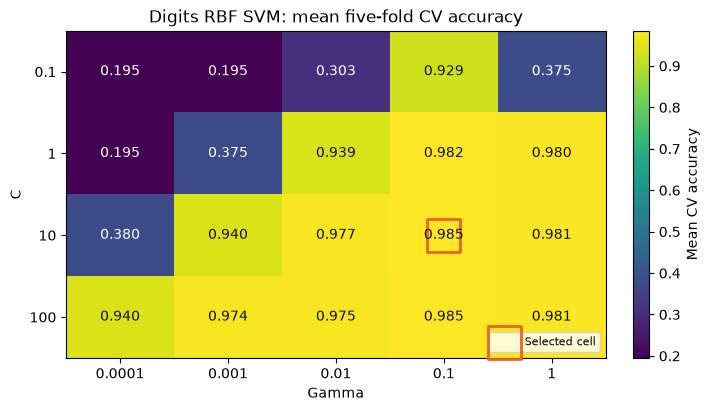

In [142]:
results = pd.DataFrame(search.cv_results_)

heat = results.pivot(index="param_C", columns="param_gamma", values="mean_test_score")

heat = heat.loc[C_grid, gamma_grid]

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)

im = ax.imshow(heat, aspect="auto", cmap="viridis")

ax.set(xticks=range(len(gamma_grid)), xticklabels=[f"{v:g}" for v in gamma_grid],
       yticks=range(len(C_grid)), yticklabels=[f"{v:g}" for v in C_grid],
       xlabel="Gamma", ylabel="C", title="Digits RBF SVM: mean five-fold CV accuracy")

for (i, j), val in np.ndenumerate(heat.to_numpy()):
    ax.text(j, i, f"{val:.3f}", ha="center", va="center",
            color="#111" if im.norm(val) > .65 else "white")

fig.colorbar(im, ax=ax, label="Mean CV accuracy")

best_c, best_gamma = search.best_params_["C"], search.best_params_["gamma"]

ax.scatter(gamma_grid.index(best_gamma), C_grid.index(best_c), marker="s",
           facecolors="none", edgecolors="#e86528", s=560, linewidths=2, label="Selected cell")

ax.legend(loc="lower right", fontsize=8)

plt.show()

In [143]:
digits_rbf_test = accuracy(dye, search.predict(d_test))

print(f"Best C={best_c:g}, gamma={best_gamma:g}, CV={search.best_score_:.6f}, test={digits_rbf_test:.6f}")

print("Near or above 0.98 (within half a percentage point):",
      search.best_score_ >= .975, digits_rbf_test >= .975)

Best C=10, gamma=0.1, CV=0.985146, test=0.991667
Near or above 0.98 (within half a percentage point): True True


Small gamma makes points broadly similar, so larger C can help separate them. Increasing gamma adds flexibility and can reduce the C needed for a good fit. This gives the good cells a roughly diagonal pattern.

C=10 and gamma=0.1 gave 98.51% mean CV accuracy and 99.17% test accuracy.

# Part F

## 30

Logistic labels are 0 or 1; binary SVM labels are −1 or +1. Here, p is the predicted probability and e_y is the one-hot target.

| Model | Loss for one sample | Score derivative | Output |
|---|---|---|---|
| Linear regression | $\frac12(s-y)^2$ | $s-y$ | Predicted number |
| Logistic regression | $\log(1+e^s)-ys$ | $\sigma(s)-y$ | Class 1 probability |
| Softmax | $\log\sum_j e^{s_j}-s_y$ | $p-e_y$ | Class probabilities |
| Binary SVM | $\max(0,1-ys)$ | $-y\,\mathbf1[ys<1]$ | Class from score sign |
| Multiclass SVM | $\sum_{j\ne y}\max(0,s_j-s_y+1)$ | $q$ defined below | Class with largest score |

For each rival class, q is 1 if its margin is violated and 0 otherwise. The correct class entry is minus the number of violating rivals. At a hinge kink, this implementation uses zero for that term.

Squared loss: differentiating the square gives twice the error, which cancels the factor of one half.

Logistic loss: differentiating the log term gives the sigmoid, then subtracting the target gives the derivative.

Softmax loss: differentiating log-sum-exp gives the probability vector, then subtracting the correct score removes the one-hot target.

Hinge loss: the active branch is linear, and the inactive branch is zero. Each active rival contributes +1 to its own derivative and −1 to the correct class derivative.

Linear regression, logistic regression and softmax have prediction-minus-target derivatives. Hinge only responds to violated margins and becomes zero once they are satisfied.

## 31

I would use ridge to predict a number, logistic regression for two classes, and softmax for several classes. Linear SVM is useful for a straight boundary; a kernel SVM can fit a curved one. On Digits, RBF reached 99.17% test accuracy, softmax 95.28%, and hinge 95.00%.

Logistic and softmax estimate probabilities, but calibration needs checking. SVM gives margin scores. Ridge predicts a number.

A badly misclassified outlier causes quadratic growth in squared loss and roughly linear growth in logistic and hinge loss.

For linear models, each training pass scales with rows times features; prediction scales with features. Multiclass models also depend on the number of classes. A direct ridge solve adds a feature-cubed cost. Kernel training generally grows faster with the number of rows, and prediction depends on the support-vector count.

I was surprised that gamma 100 gave 98.24% training accuracy but only 73.68% validation accuracy.